# 08 Image Model (Single-Mode)

**Question.** Given a news photo, was **the image itself** visually manipulated, by a face swap (`face_swap`) or a facial attribute edit (`face_attribute`)?

**Output.** One score per dataset row, `p_image_tampered`, between 0 and 1. Higher means the image looks more manipulated. An image is **called tampered when its score is at or above a threshold**. Two thresholds are chosen on validation (section 6): one that maximises F1 (the main result, comparable with `05` and `06`), and a strict one that flags only 1% of untouched images (a realistic operating point).

This is an **image-level** score, **not** a prediction of whether the news pair is fake. An untouched photo with a swapped caption counts as a negative here, because its pixels were not edited. Together with the text model (`06`), this is one of the single-mode baselines that the multimodal model (`05`) is compared against.

**Two models are built, with the same method and different CLIP encoders:**

| | Main model (sections 4–9) | Lightweight model (section 10) |
|---|---|---|
| Whole images | ViT-L/14 (large) | ViT-B/32 (small) |
| Face crops | ViT-B/16 | ViT-B/32 |
| Embeddings | computed in notebook `04`, reused here | computed here |
| When to use it | best accuracy | when speed matters: high volume, early screening, modest hardware |

Section 11 compares them on accuracy and on speed measured on this machine.

**Results at a glance** (test set, 50,705 rows, F1 threshold): 

| Model | ROC-AUC | EER | Accuracy | Precision | Recall | F1 | Speed on this Mac |
|---|---|---|---|---|---|---|---|
| Majority class (always "manipulated") | 0.500 | 0.500 | 0.531 | 0.531 | 1.000 | 0.693 | – |
| **Main** (ViT-L/14 + ViT-B/16) | **0.854** | **0.239** | **0.749** | **0.712** | **0.884** | **0.789** | about 4–4.5 images/s |
| Lightweight (ViT-B/32) | 0.820 | 0.269 | 0.722 | 0.688 | 0.874 | 0.770 | about 25–27 images/s (about 6× faster) |

Details are in sections 8, 10 and 11 and the Summary.

### How to read this notebook

| Section | What it does | What to look at |
|---|---|---|
| 0 Setup | imports, settings, records versions and dataset revision | `run_info` |
| 1 Labels | builds the image label from `fake_cls` and checks it against `02` | the 9-combination table |
| 2 Image files | checks that every image path opens as a JPG | missing / unreadable counts |
| 3 Overlap | measures shared articles and identical images across splits | overlap table |
| 4 Embeddings | sets up the face crops for both models | crop statistics by class |
| 4.1 Face EDA | faces per image, face size, whether the edited face is the largest | why faces are cropped and averaged |
| 4.2 Load embeddings | loads `04`'s ViT-L/14 and ViT-B/16 vectors and checks they line up | the two alignment checks |
| 5 Models | main model: a logistic regression for each of the 3 input variants | cross-validated AUC |
| 6 Selection | picks the main model's variant and two thresholds on validation | `CONFIG` |
| 7 Error analysis | where the main model fails, on validation | breakdowns by type, generator, publisher, face count |
| 8 Test | one evaluation of the main model | results table, confusion matrix |
| 9 Save | writes the main model's row-level predictions for the team | file list |
| 10 Lightweight model | the same steps with the small ViT-B/32 encoder | selection, test results |
| 11 Comparison | main vs lightweight: accuracy, and speed measured here | accuracy and speed tables |

### Terms used below

| Term | Meaning |
|---|---|
| row vs image | A dataset row is one image-caption pair. One untouched photo can appear in several rows (its original pair and its text-only edits), so there are fewer distinct images than rows. The model is fit on distinct images; results are reported on rows. |
| encoder | The frozen CLIP network that turns a picture into numbers. Larger encoders see finer detail but run slower. |
| variant | Which picture the classifier sees: the whole image, the faces only, or both (section 5). Only one variant per model is kept, chosen on validation. |
| ROC-AUC | Chance that a random manipulated image scores higher than a random untouched one. 0.5 = guessing, 1 = perfect. Does not depend on the threshold. |
| EER | Equal Error Rate: the error rate at the threshold where false alarms and misses are equally common. Lower is better. Does not depend on the threshold. |
| precision / recall / F1 | Of the images called tampered, the share that really are (precision); of the truly tampered images, the share caught (recall); F1 balances the two. These depend on the threshold. |
| out-of-fold | A training image's score from a model that did not see that image's article while fitting. Used so a model stacked on top is not fooled by memorised scores. |
| majority class | A trivial reference that always predicts the most common label. A useful model must beat it. |

### Method

Frozen CLIP image embeddings and a scaled logistic regression. CLIP is not trained further; only the logistic regression is fit. For each model, three inputs are compared:

| Variant | Input to the logistic regression |
|---|---|
| `full_image` | embedding of the whole image |
| `face_mean` | mean embedding of the image's MTCNN face crops, or the whole image if it has no usable crop |
| `full_plus_face` | both, concatenated |

**What the model never sees:** captions, file paths, ids, `fake_cls`, `fake_image_box`, `fake_text_pos`. The path alone gives the label away: untouched images are in `DGM4/origin/` and edited ones in `DGM4/manipulation/` (`02`, section 3). Face crops come from `mtcnn_boxes`, which every image has, real or fake, and the same crop rule is applied to both. `fake_image_box` is never read.

**Data use** (as in `05` and `06`):
1. Fit on `train_sample` from `02`.
2. Choose the regularisation by grouped cross-validation on train.
3. Choose the variant and the thresholds on `validation`.
4. Evaluate the chosen configuration once on `test`.

**Running it.** From `notebooks/`: `jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 08_image_model.ipynb`, or *Restart & Run All*. It needs:
- `02` to have been run first
- `04`'s embeddings in `data/interim/clip/` and `data/features/`. Without them, the main model's embeddings are computed here instead, which takes several hours.

The first run also embeds everything with ViT-B/32 for the lightweight model (about 70 minutes on this Mac). Later runs reuse every cache and take a few minutes. Full instructions are in `docs/image_baseline.md`.

**Smoke test.** `IMAGE_SMOKE_TEST=1` runs everything on 40 rows per `fake_cls` per split (seeded, so both classes are present). It writes only to `data/interim/image_model/smoke/`.

## 0. Setup

Imports, fixed settings and output folders. Every choice that affects results (the three CLIP checkpoints, seed, folds, regularisation grid) is a named constant here, so it is visible in one place and saved with the predictions.

In [1]:
import json
import os
import platform
import sys
import time
from multiprocessing import Pool
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import torch
import transformers
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

# The notebook runs from notebooks/, so the shared code in src/ is one level up
PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from huggingface_hub import hf_hub_download
from transformers.utils import logging as hf_logging
# Team code reused unchanged: CLIP loading and batched embedding (04), shared metrics (05/06), zip image reader (03/04)
from src.clip_features import FACE_MARGIN, ImageDataset, best_device, encode_images, encode_images_chunked, load_clip
from src.evaluation import best_f1_threshold, binary_metrics, detection_rate_by_type
from src.images import archive_for, open_archive
# New for this notebook (tested in tests/test_image_model.py): label rule, file check, face-crop rule, face pooling
from src.image_model import (MIN_FACE_SIDE, check_image_safe, image_tampered_from_fake_cls, mean_face_embedding,
                             valid_face_boxes)

hf_logging.disable_progress_bar()

REPO_ID = "rshaojimmy/DGM4"                     # dataset on the Hugging Face Hub
# Frozen CLIP image encoders (never trained here). All read a 224x224 picture cut into square patches.
MAIN_IMAGE_ENCODER = "openai/clip-vit-large-patch14"  # main model, whole images: 768 numbers, 14 px patches (as in 04)
MAIN_FACE_ENCODER = "openai/clip-vit-base-patch16"    # main model, face crops: 512 numbers, 16 px patches (as in 04)
LIGHT_ENCODER = "openai/clip-vit-base-patch32"        # lightweight model, both: 512 numbers, 32 px patches (section 10)
RANDOM_STATE = 4012                             # same seed as 02, 04 and 05
N_FOLDS = 5                                     # cross-validation folds, grouped by article id
C_GRID = (0.001, 0.01, 0.1, 1.0)                # logistic regression strengths tried (smaller C = stronger regularisation)
VARIANTS = ["full_image", "face_mean", "full_plus_face"]
TARGET_FPR = 0.01                               # the strict threshold flags 1% of untouched validation images
NUM_WORKERS = max(1, (os.cpu_count() or 2) - 2) # processes for decoding JPGs

# The test split is used only in section 8, after the configuration is frozen in section 6
RUN_TEST = True

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"           # splits written by 02
CACHE_DIR = PROJECT_ROOT / "data" / "interim" / "image_model" # file check and embedding caches (gitignored)
PREDICTIONS_DIR = PROJECT_ROOT / "results" / "predictions"    # outputs shared with the team

# Smoke test: same code on a tiny stratified sample, with its own cache and output folder so real results are untouched
SMOKE_TEST = os.environ.get("IMAGE_SMOKE_TEST") == "1"
SMOKE_ROWS_PER_CLASS = 40
if SMOKE_TEST:
    CACHE_DIR = CACHE_DIR / "smoke"
    PREDICTIONS_DIR = CACHE_DIR / "predictions"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

W1118 23:38:38.340000 99016 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
def snapshot_revision(repo_id, filename, repo_type=None):
    # hf_hub_download returns .../snapshots/<commit>/<filename>, so the commit hash is read from the path
    path = Path(hf_hub_download(repo_id, filename, repo_type=repo_type))
    return path.parents[len(Path(filename).parts) - 1].name


# Record exactly which data, weights and library versions produced these results (saved again in section 9)
DATASET_REVISION = snapshot_revision(REPO_ID, "metadata/train.json", repo_type="dataset")
CLIP_REVISIONS = {name: snapshot_revision(name, "config.json")
                  for name in [MAIN_IMAGE_ENCODER, MAIN_FACE_ENCODER, LIGHT_ENCODER]}
device = best_device()  # "mps" on Apple silicon, "cuda" on NVIDIA, else "cpu"

run_info = {
    "dataset": REPO_ID, "dataset_revision": DATASET_REVISION, "clip_revisions": CLIP_REVISIONS,
    "random_state": RANDOM_STATE, "smoke_test": SMOKE_TEST, "device": device,
    "python": platform.python_version(), "torch": torch.__version__, "transformers": transformers.__version__,
    "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
}
run_info

{'dataset': 'rshaojimmy/DGM4',
 'dataset_revision': '9efd3f1ca14cb1dac1692cdce0beea6844b968a6',
 'clip_revisions': {'openai/clip-vit-large-patch14': '32bd64288804d66eefd0ccbe215aa642df71cc41',
  'openai/clip-vit-base-patch16': '57c216476eefef5ab752ec549e440a49ae4ae5f3',
  'openai/clip-vit-base-patch32': '3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268'},
 'random_state': 4012,
 'smoke_test': False,
 'device': 'mps',
 'python': '3.11.18',
 'torch': '2.15.0',
 'transformers': '5.23.0',
 'scikit-learn': '1.9.1',
 'pandas': '3.1.1',
 'numpy': '2.4.6'}

## 1. Labels

The splits and the stable row key `row_id` come from `02_data_cleaning` (`data/processed/`). `02` already derives `image_fake`. Here the image label is rebuilt independently from the raw tags, and the two must agree on every row:
- `fake_cls` is split on `&` into tags, e.g. `face_swap&text_attribute` becomes {`face_swap`, `text_attribute`}
- `image_tampered = 1` if the tags include `face_swap` or `face_attribute`, whatever happened to the caption
- `image_tampered = 0` for `orig`, `text_swap` and `text_attribute`, because the pixels are untouched
- anything outside the nine DGM4 combinations raises an error (`src/image_model.py`, tested in `tests/test_image_model.py`)

In [3]:
SPLITS = ["train_sample", "validation", "test"]                    # the three sets the model uses
OFFICIAL = {"train": "train", "validation": "val", "test": "test"}  # processed name -> raw metadata file name

# 02's cleaned splits, plus the raw metadata files they came from (used to count raw rows and check row order)
data = {name: pd.read_parquet(PROCESSED_DIR / f"{name}.parquet") for name in ["train", *SPLITS]}
raw = {name: pd.read_json(hf_hub_download(REPO_ID, f"metadata/{f}.json", repo_type="dataset"))
       for name, f in OFFICIAL.items()}

# Build the image label from the tags and check it against 02's image_fake
for df in [*data.values(), *raw.values()]:
    df["image_tampered"] = df["fake_cls"].map(image_tampered_from_fake_cls).astype("int8")
for name, df in data.items():
    assert (df["image_tampered"] == df["image_fake"]).all(), f"{name}: image label disagrees with 02"

# row_id is positional (e.g. test_000123 is the 124th row), so check that 02's rows are exactly the metadata rows,
# in the same order, after its de-duplication. Otherwise predictions would join to the wrong rows.
key = ["id", "text", "image", "fake_cls"]
for name, df in raw.items():
    expected = df.drop_duplicates(key).reset_index(drop=True)
    assert len(expected) == len(data[name]) and all(
        (expected[c].to_numpy() == data[name][c].to_numpy()).all() for c in key
    ), f"{name}: rows differ from metadata/{OFFICIAL[name]}.json"
print("image_tampered matches 02's image_fake on every row; 02's rows match the metadata files in order")

image_tampered matches 02's image_fake on every row; 02's rows match the metadata files in order


In [4]:
# The nine fake_cls combinations, the label each one gets, and how many rows each split has (after 02's de-duplication)
by_split = pd.concat([data[s][["fake_cls"]].assign(split=s) for s in ["train", "validation", "test"]])
combos = pd.crosstab(by_split["fake_cls"], by_split["split"])[["train", "validation", "test"]]
combos.insert(0, "image_tampered", combos.index.map(image_tampered_from_fake_cls))
assert len(combos) == 9  # no unexpected combinations in the data
combos.sort_values(["image_tampered", "train"], ascending=[True, False])

split,image_tampered,train,validation,test
fake_cls,,,,
orig,0,53077,7473,16876
text_swap,0,13788,1894,4952
text_attribute,0,6009,825,1973
face_swap,1,33704,4788,10515
face_attribute,1,28513,3999,8921
face_swap&text_swap,1,8317,1163,2935
face_attribute&text_swap,1,7004,964,2529
face_swap&text_attribute,1,3649,533,1118
face_attribute&text_attribute,1,3108,487,886


**Reading the output.** The top three combinations have untouched pixels and get label 0, including the two caption-only edits. The bottom six all contain a face edit and get label 1, whether or not the caption was also changed.

In [5]:
def split_summary(df):
    # Row counts and label balance for one split, counted both per row and per distinct image
    per_image = df.drop_duplicates("image")
    return {
        "rows": len(df),
        "distinct images": per_image.shape[0],
        "distinct ids": df["id"].nunique(),
        "max rows per image": df["image"].value_counts().max(),
        "% image_tampered (rows)": 100 * df["image_tampered"].mean(),
        "% image_tampered (distinct images)": 100 * per_image["image_tampered"].mean(),
    }


# "(metadata)" rows are the raw files; the others are 02's cleaned splits (train loses 51,015 repeated orig rows)
summary = pd.DataFrame({
    **{f"{name} (metadata)": split_summary(df) for name, df in raw.items()},
    **{name: split_summary(df) for name, df in data.items()},
}).T
display(summary.round(2))

# Each image has a single label and belongs to a single article, within and across splits.
# This is what makes it safe to fit one score per image and copy it to every row that shows the image.
everything = pd.concat([*raw.values(), *data.values()])
assert everything.groupby("image")["image_tampered"].nunique().eq(1).all(), "an image has two labels"
assert everything.groupby("image")["id"].nunique().eq(1).all(), "an image belongs to two articles"
print("every image has one label and one article id")

,rows,distinct images,distinct ids,max rows per image,% image_tampered (rows),% image_tampered (distinct images)
train (metadata),208184.0,141189.0,56894.0,5.0,40.49,59.70
validation (metadata),22126.0,19909.0,7975.0,3.0,53.94,59.94
test (metadata),50705.0,45264.0,18360.0,3.0,53.06,59.44
train,157169.0,141189.0,56894.0,3.0,53.63,59.70
train_sample,49943.0,44857.0,18100.0,3.0,53.58,59.65
validation,22126.0,19909.0,7975.0,3.0,53.94,59.94
test,50705.0,45264.0,18360.0,3.0,53.06,59.44


every image has one label and one article id


**Reading the output.** Just over half of the rows (53–54%) have a manipulated image. A larger share of distinct images do (about 60%), because one untouched photo is shared by its `orig` row and its text-only edits. The model is trained on `train_sample`: 49,943 rows, 44,857 distinct images and 18,100 articles. The majority-class reference in section 8 always predicts the most common `train_sample` label, which is "manipulated".

In [6]:
# Smoke test only: keep a few rows of every fake_cls in each split so both labels are present.
# Full train is cut down to the same images, so the file and overlap checks below stay fast.
if SMOKE_TEST:
    for s in SPLITS:
        data[s] = (data[s].sample(frac=1, random_state=RANDOM_STATE).groupby("fake_cls").head(SMOKE_ROWS_PER_CLASS)
                   .sort_values("row_id").reset_index(drop=True))
    data["train"] = data["train"][data["train"]["image"].isin(data["train_sample"]["image"])].reset_index(drop=True)
    print("SMOKE TEST:", {s: len(df) for s, df in data.items()})

## 2. Image Files

The `image` paths are relative to the dataset root. Each one resolves to a JPG inside one of the eight Hugging Face zips (`src/images.py`): `DGM4/<origin|manipulation>/<source>/<rest>` is the member `<source>/<rest>` of `<origin|manipulation>/<source>.zip`. Images are read straight from the zips, so nothing needs unpacking.

Every distinct image of the official splits is read and fully decoded once. This also records:
- its MD5 hash, used in section 3 to find byte-identical images
- its width and height, used in section 4 to clip face boxes to the picture

In [7]:
# One example path per source folder, showing which zip and which member it resolves to
examples = pd.concat([data["validation"].drop_duplicates("image_source"), data["train"].drop_duplicates("image_source")]
                     ).drop_duplicates("image_source").sort_values("image_source")
resolution = []
for path in examples["image"]:
    archive, index = open_archive(archive_for(path))
    member = index["/".join(path.removeprefix("DGM4/").split("/")[2:])]
    resolution.append({"image": path, "zip": archive_for(path), "member": member})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(resolution))

,image,zip,member
0,DGM4/manipulation/HFGI/1675978-HFGI.jpg,manipulation/HFGI.zip,HFGI/1675978-HFGI.jpg
1,DGM4/manipulation/StyleCLIP/538309-StyleCLIP.jpg,manipulation/StyleCLIP.zip,StyleCLIP/538309-StyleCLIP.jpg
2,DGM4/manipulation/infoswap/649778-081830-infoswap.jpg,manipulation/infoswap.zip,infoswap/649778-081830-infoswap.jpg
3,DGM4/manipulation/simswap/683133-013337-simswap.jpg,manipulation/simswap.zip,simswap/683133-013337-simswap.jpg
4,DGM4/origin/bbc/0272/120.jpg,origin/bbc.zip,bbc/0272/120.jpg
5,DGM4/origin/guardian/0815/137.jpg,origin/guardian.zip,guardian/0815/137.jpg
6,DGM4/origin/usa_today/0048/120.jpg,origin/usa_today.zip,usa_today/0048/120.jpg
7,DGM4/origin/washington_post/0530/050.jpg,origin/washington_post.zip,washington_post/0530/050.jpg


In [8]:
# Check every distinct image of the full official splits (not only the ones the model uses)
official = {"train": data["train"], "validation": data["validation"], "test": data["test"]}

image_split = pd.concat([df[["image"]].assign(split=name) for name, df in official.items()]).drop_duplicates("image")
FILE_CHECK_PATH = CACHE_DIR / "file_check.parquet"
if FILE_CHECK_PATH.exists() and set(image_split["image"]) <= set(pd.read_parquet(FILE_CHECK_PATH, columns=["image"])["image"]):
    # Already checked in an earlier run
    files = pd.read_parquet(FILE_CHECK_PATH)
    print("file check: loaded from cache")
else:
    start = time.time()
    paths = sorted(image_split["image"])  # sorted by path, so each worker reads one zip at a time
    with Pool(NUM_WORKERS) as pool:
        # check_image_safe never raises: a bad file is reported in its "error" field instead of stopping the run
        files = pd.DataFrame(pool.map(check_image_safe, paths, chunksize=500))
    files.to_parquet(FILE_CHECK_PATH, index=False)
    print(f"file check: {len(files):,} images in {(time.time() - start) / 60:.1f} min")

# Status per image: ok, missing (path not in its zip) or unreadable (in the zip but fails to decode)
files = image_split.merge(files, on="image", how="left")
files["status"] = np.select([files["error"].isna(), files["error"].eq("missing")], ["ok", "missing"], "unreadable")
display(files.groupby("split")["status"].value_counts().unstack(fill_value=0)
        .reindex(columns=["ok", "missing", "unreadable"], fill_value=0).loc[list(official)])
display(files.groupby("split")["mode"].value_counts().unstack(fill_value=0))  # colour mode, e.g. RGB or greyscale
if (files["status"] != "ok").any():
    display(files.loc[files["status"] != "ok", ["split", "image", "error"]].head(20))

file check: loaded from cache


status,ok,missing,unreadable
split,,,
train,141189,0,0
validation,19909,0,0
test,45264,0,0


mode,RGB
split,
test,45264
train,141189
validation,19909


**Reading the output.** All 206,362 distinct images of the official splits open and decode, and all are RGB. No file is missing or unreadable, so no rows have to be dropped.

## 3. Overlap Between Splits

If the same image appears in both training and test data, the model could score it well by memory rather than by spotting the edit. The splits are used as they are: the official DGM4 splits, with `train_sample` drawn from train by article in `02`. Overlap is measured here, not removed.

Three keys are checked, from loosest to strictest:
- article `id`
- image path
- the exact MD5 hash of the file: the same MD5 under two paths means byte-identical images

In [9]:
md5 = files.set_index("image")["md5"]
sets = {**official, "train_sample": data["train_sample"]}


def overlap(a, b):
    # How much splits a and b share, by article id, by path and by exact file content
    A, B = sets[a], sets[b]
    shared_md5 = set(md5.reindex(A["image"].unique()).dropna()) & set(md5.reindex(B["image"].unique()).dropna())
    rows_b = B["image"].map(md5).isin(shared_md5)
    return {"shared ids": len(set(A["id"]) & set(B["id"])),
            "shared image paths": len(set(A["image"]) & set(B["image"])),
            "shared exact images (MD5)": len(shared_md5),
            f"rows of the 2nd split with such an image": int(rows_b.sum())}


pairs = [("train", "validation"), ("train", "test"), ("validation", "test"),
         ("train_sample", "validation"), ("train_sample", "test")]
display(pd.DataFrame({f"{a} vs {b}": overlap(a, b) for a, b in pairs}).T)

# Byte-identical files stored under different paths (anywhere), and whether any of them carry different labels
labelled = pd.concat([df[["image", "image_tampered"]] for df in official.values()]).drop_duplicates("image")
labelled["md5"] = labelled["image"].map(md5)
by_md5 = labelled.dropna(subset=["md5"]).groupby("md5").agg(paths=("image", "size"), labels=("image_tampered", "nunique"))
print(f"MD5 values shared by more than one path: {(by_md5['paths'] > 1).sum():,} "
      f"({by_md5.loc[by_md5['paths'] > 1, 'paths'].sum():,} paths); with conflicting labels: {(by_md5['labels'] > 1).sum():,}")

,shared ids,shared image paths,shared exact images (MD5),rows of the 2nd split with such an image
train vs validation,0,0,24,26
train vs test,0,0,56,66
validation vs test,0,0,7,14
train_sample vs validation,0,0,7,7
train_sample vs test,0,0,17,18


MD5 values shared by more than one path: 251 (519 paths); with conflicting labels: 0


In [10]:
# Validation and test rows whose article or exact image also appears in train_sample, the data the model is fit on.
# They stay in the evaluation; section 8 also reports the test results without them.
train_ids = set(data["train_sample"]["id"])
train_md5 = set(data["train_sample"]["image"].map(md5).dropna())


def seen_in_train(df):
    # True for rows the model might partly recognise from training
    return (df["id"].isin(train_ids) | df["image"].map(md5).isin(train_md5)).to_numpy()


pd.Series({s: int(seen_in_train(data[s]).sum()) for s in SPLITS[1:]}, name="rows overlapping train_sample")

validation     7
test          18
Name: rows overlapping train_sample, dtype: int64

**Reading the output.** No article or path is shared between splits. A small number of byte-identical photos are (for example 56 between train and test), most likely the same news photo scraped twice. Only 7 validation rows and 18 test rows share an exact image with `train_sample`, and none of these duplicates carry conflicting labels. That is too few to affect the results; section 8 confirms it.

## 4. CLIP Embeddings for the Main Model

This section **embeds each image into vector form**, the input the logistic regression in section 5 learns from.

1. **CLIP converts each picture into a vector:** a fixed-length list of numbers (768 or 512, depending on the encoder) that summarises what the picture looks like. Similar-looking pictures get similar vectors.
2. **The logistic regression learns from these vectors** which patterns go with manipulated images, and turns each vector into a score between 0 and 1.

CLIP is a large pre-trained neural network, and it stays **frozen**: its weights are never changed here. It is used only as a feature extractor. The only part trained on DGM4 is the logistic regression, which is a simple linear model, not a neural network.

The main model uses the two encoders from notebook `04`:

| What is embedded | Encoder | Numbers per picture | How CLIP cuts up the 224×224 input |
|---|---|---|---|
| each **whole image** | ViT-L/14 (`openai/clip-vit-large-patch14`), large network, 24 layers | 768 | 16×16 = 256 squares of 14 px |
| each **face crop** | ViT-B/16 (`openai/clip-vit-base-patch16`), base network, 12 layers | 512 | 14×14 = 196 squares of 16 px |

**Where the embeddings come from.** Chloe computed them when she ran `04`, and they are reused here from `data/interim/clip/`, not recomputed:
- `images.npy`: one ViT-L/14 vector per distinct image
- `faces_vitb16.npy`: one ViT-B/16 vector per MTCNN box

`04` kept the order of these arrays implicit: distinct images of `train_sample`, `validation`, `test`, in that order, with faces in box order. The code below rebuilds that order from `02`'s splits and checks it twice before using any vector (section 4.2). If the folder is missing, the notebook computes the same embeddings itself with the shared `src/clip_features` code and caches them in `data/interim/image_model/`. That takes several hours on a laptop and resumes if interrupted.

**Face crops.** Each `mtcnn_boxes` box is clipped to the image and kept if both sides are at least `MIN_FACE_SIDE` = 16 pixels (`src/image_model.valid_face_boxes`). Kept boxes are enlarged by `FACE_MARGIN` = 20% on every side (`src/clip_features.crop_face`, as in `04`) so the crop includes hair and jaw. The rule depends only on the detector boxes and the image size, so it is the same for real and manipulated images. `04` embedded every box, including the few tiny ones; only the boxes that pass this rule are used. An image's face embedding is the mean of its crop embeddings, re-normalised to unit length. An image with no valid crop falls back to its whole image, embedded with the face encoder.

**Why crops might help.** CLIP resizes every photo to 224×224 pixels before reading it. A typical face covers about 2% of a news photo, so it ends up about 33 px wide (section 4.1): only a few squares of the encoder's grid. At that size, blending seams and generator textures are mostly averaged away. A crop gives the face the whole input.

**Why averaging might hurt.** An image usually has several detected faces, but only one is edited. Averaging k face embeddings dilutes the edited face's signal by roughly 1/k, so the gain from cropping should shrink as the number of faces grows; section 7 checks this. Picking the most suspicious face instead would need face-level labels, which only come from `fake_image_box`, so it is not done here.

In [11]:
# All rows the model will score, with the split each belongs to
model_rows = pd.concat([data[s].assign(split=s) for s in SPLITS], ignore_index=True)

# Every row of an image carries the same MTCNN boxes, so boxes can be taken from any one of its rows
box_text = model_rows["mtcnn_boxes"].map(lambda boxes: str([list(map(int, b)) for b in boxes]))
assert box_text.groupby(model_rows["image"]).nunique().eq(1).all()

# One row per distinct image: this is the unit the classifier is fit on
images = model_rows.drop_duplicates("image")[["image", "id", "image_tampered", "mtcnn_boxes"]].reset_index(drop=True)
images = images.merge(files[["image", "width", "height", "status"]], on="image", how="left")
assert images["status"].eq("ok").all(), "some images used by the model could not be read (section 2)"
images[["width", "height"]] = images[["width", "height"]].astype(int)
image_index = pd.Series(np.arange(len(images)), index=images["image"])  # image path -> row in the embedding arrays
print(f"{len(model_rows):,} rows | {len(images):,} distinct images")


def cached_index(name, frame):
    # An embedding cache is a plain array (row k = item k), so the item order is saved next to it and must
    # match on every re-run; otherwise embeddings would be attached to the wrong images
    path = CACHE_DIR / f"{name}_index.parquet"
    if path.exists():
        saved = pd.read_parquet(path)
        assert saved.equals(frame.reset_index(drop=True)), f"{path.name} does not match; delete {name}_* in {CACHE_DIR}"
    else:
        frame.reset_index(drop=True).to_parquet(path, index=False)


# One row per valid face crop: which image it belongs to (image_idx) and its clipped box.
# The same list is used by the main model and by the lightweight model in section 10.
faces = pd.DataFrame(
    [(i, *box) for i, (boxes, w, h) in enumerate(zip(images["mtcnn_boxes"], images["width"], images["height"]))
     for box in valid_face_boxes(boxes, w, h)],
    columns=["image_idx", "x1", "y1", "x2", "y2"])
faces["image"] = images["image"].to_numpy()[faces["image_idx"]]
face_boxes = faces[["x1", "y1", "x2", "y2"]].to_numpy().tolist()

122,774 rows | 110,030 distinct images


In [12]:
# Face crops per image, by class. If one class lost many more boxes, or fell back to the whole image more often,
# "number of faces" or "fallback used" would become a hint about the label (a shortcut), so the two must look alike.
images["n_mtcnn"] = images["mtcnn_boxes"].str.len()
images["n_valid_faces"] = np.bincount(faces["image_idx"], minlength=len(images))
crop_stats = images.groupby("image_tampered").agg(
    images=("image", "size"),
    mean_mtcnn_boxes=("n_mtcnn", "mean"),
    mean_valid_crops=("n_valid_faces", "mean"),
    pct_boxes_dropped=("n_valid_faces", lambda v: 100 * (1 - v.sum() / images.loc[v.index, "n_mtcnn"].sum())),
    pct_full_image_fallback=("n_valid_faces", lambda v: 100 * (v == 0).mean()),
)
crop_stats.round(2)

,images,mean_mtcnn_boxes,mean_valid_crops,pct_boxes_dropped,pct_full_image_fallback
image_tampered,,,,,
0,44435,2.69,2.59,3.74,0.0
1,65595,2.67,2.59,2.83,0.0


**Reading the output.** Both classes have about 2.7 detected faces per image and 2.6 valid crops after the size rule. The small-box rule drops a similar share of boxes (3.7% for untouched, 2.8% for manipulated images). Only one image of the 110,030 has no valid crop and falls back to its whole image. The crop rule therefore does not give the label away.

### 4.1 What the Faces Look Like

A short exploration of the faces, on the distinct images of `train_sample` only; validation and test stay untouched for evaluation. Face count is **not** used as a model input. The three questions below each test one of the design choices made above:

1. **How many faces does a picture have, and does it differ by class?** If manipulated images had more or fewer faces, the face count alone would reveal the label. If most pictures have several faces, a single edited face is a small part of the image.
2. **How big is a face?** This decides how much of a face CLIP can see in the whole image (why crop).
3. **Is the edited face usually the largest one?** If it always were, using the largest face would beat averaging (why average).

Question 3 needs `fake_image_box`, the location of the edited face. **This is its only use in the notebook.** It is read here only to describe the data and never reaches the model, the crop rule or any feature.

,count,mean,50%,min,max
class,,,,,
manipulated,26757.0,2.59,2.0,1.0,5.0
untouched,18100.0,2.59,2.0,1.0,5.0


class,untouched,manipulated
valid faces,,
1,2.6,2.1
2,58.1,59.1
3,22.3,22.0
4,11.6,11.3
5,5.4,5.5


,median face share of image,median face width at 224 px
class,,
manipulated,0.023,34.017
untouched,0.021,32.073


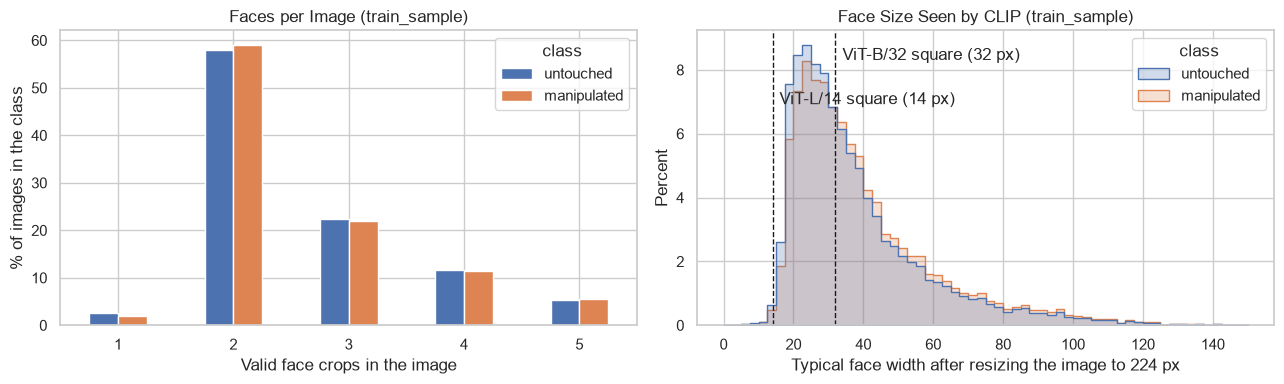

edited face is the largest face in 66.5% of 26,757 manipulated images; one of 2.59 faces on average is edited


In [13]:
in_train_sample = images["image"].isin(data["train_sample"]["image"]).to_numpy()  # train_sample images only
eda = images[in_train_sample].copy()
eda["class"] = eda["image_tampered"].map({0: "untouched", 1: "manipulated"})

# 1. Valid face crops per image, as % of each class
face_counts = pd.crosstab(eda["n_valid_faces"], eda["class"], normalize="columns").mul(100)[["untouched", "manipulated"]]
display(eda.groupby("class")["n_valid_faces"].describe()[["count", "mean", "50%", "min", "max"]].round(2))
display(face_counts.round(1).rename_axis("valid faces"))

# 2. Face size: each image's median face area as a share of the picture, and its width after CLIP's 224x224 resize
face_area = (faces["x2"] - faces["x1"]) * (faces["y2"] - faces["y1"])
image_area = (images["width"] * images["height"]).to_numpy()[faces["image_idx"]]
median_share = (face_area / image_area).groupby(faces["image_idx"]).median()
eda["face_share"] = median_share.reindex(np.flatnonzero(in_train_sample)).to_numpy()
eda["face_px_at_224"] = 224 * np.sqrt(eda["face_share"])
display(eda.groupby("class")[["face_share", "face_px_at_224"]].median().round(3)
        .rename(columns={"face_share": "median face share of image", "face_px_at_224": "median face width at 224 px"}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
face_counts.plot.bar(ax=axes[0], rot=0)
axes[0].set_xlabel("Valid face crops in the image")
axes[0].set_ylabel("% of images in the class")
axes[0].set_title("Faces per Image (train_sample)")
sns.histplot(data=eda, x="face_px_at_224", hue="class", hue_order=["untouched", "manipulated"], bins=60,
             binrange=(0, 150), stat="percent", common_norm=False, element="step", ax=axes[1])
for px, name in [(14, "ViT-L/14 square (14 px)"), (32, "ViT-B/32 square (32 px)")]:
    axes[1].axvline(px, color="k", ls="--", lw=1)
    axes[1].text(px + 2, axes[1].get_ylim()[1] * (0.9 if px == 32 else 0.75), name)
axes[1].set_xlabel("Typical face width after resizing the image to 224 px")
axes[1].set_title("Face Size Seen by CLIP (train_sample)")
plt.tight_layout()
plt.show()

# 3. Is the edited face the largest face? (fake_image_box read for description only, see above)
manipulated = data["train_sample"][data["train_sample"]["image_tampered"] == 1].drop_duplicates("image")


def edited_is_largest(row):
    areas = [(b[2] - b[0]) * (b[3] - b[1]) for b in row["mtcnn_boxes"]]
    return list(map(int, row["mtcnn_boxes"][int(np.argmax(areas))])) == list(map(int, row["fake_image_box"]))


share_largest = manipulated.apply(edited_is_largest, axis=1).mean()
print(f"edited face is the largest face in {100 * share_largest:.1f}% of {len(manipulated):,} manipulated images; "
      f"one of {eda.loc[eda['image_tampered'] == 1, 'n_valid_faces'].mean():.2f} faces on average is edited")

**Reading the output.**
1. **Face count is the same for both classes:** a mean of 2.59 valid faces per image, with exactly 2 faces in about 58–59% and 4 or more in about 17% of images. Face count therefore cannot separate real from fake; the model has to look at the pixels. Every picture has at least one valid face, and about 97% have two or more, so the edited face is almost never the only face in the picture.
2. **Faces are small.** A typical face covers about 2% of the picture, so after CLIP shrinks the image to 224×224 it is about 32–34 px wide. For the main model's ViT-L/14 that is roughly 2×2 of its 14 px squares (out of 256); for the lightweight ViT-B/32 in section 10 it is a single 32 px square (out of 49). This is why cropping the faces helps both models, and why it matters more for the small one.
3. **The edited face is the largest only about two-thirds of the time** (66.5%). Picking the largest face would miss the edit in a third of manipulated images, so all faces are averaged instead. The cost is dilution: one edited face among about 2.6 is averaged with unedited ones. Section 7 shows the face-crop AUC falling as the number of faces rises.

### 4.2 Load and Check the Embeddings

The vectors are matched to 08's images **by path**, using the rebuilt `04` order. Two checks run before any vector is used:
1. **Whole images:** the ViT-L/14 vectors must equal the per-row copies `04` saved for `05` in `data/features/clip_emb_*.parquet`.
2. **Faces:** the face array is long and has no index, so a wrong offset would silently attach faces to the wrong images. 200 random kept crops are re-embedded here with ViT-B/16 and must match `04`'s vectors (cosine ≈ 1). `04` adds the 20% margin before clipping a box to the image and 08 clips first, so only boxes at the image edge can differ slightly; they are reported separately.

In [14]:
CLIP04_DIR = PROJECT_ROOT / "data" / "interim" / "clip"
FEATURES04_DIR = PROJECT_ROOT / "data" / "features"
# Set IMAGE_RECOMPUTE_MAIN=1 to ignore 04's files and compute the main embeddings here (tests that path)
USE_04_EMBEDDINGS = ((CLIP04_DIR / "images.npy").exists() and (CLIP04_DIR / "faces_vitb16.npy").exists()
                     and os.environ.get("IMAGE_RECOMPUTE_MAIN") != "1")

if USE_04_EMBEDDINGS:
    # Rebuild 04's order: distinct images of train_sample, validation, test (02's full files, not the smoke sample),
    # and the position of each image's first box in the face array
    order04 = pd.concat([pd.read_parquet(PROCESSED_DIR / f"{s}.parquet", columns=["image", "mtcnn_boxes"]) for s in SPLITS],
                        ignore_index=True).drop_duplicates("image").reset_index(drop=True)
    boxes04 = order04["mtcnn_boxes"].str.len().to_numpy()
    first_box04 = np.concatenate([[0], np.cumsum(boxes04)[:-1]])

    l14_all = np.load(CLIP04_DIR / "images.npy", mmap_mode="r")
    b16_all = np.load(CLIP04_DIR / "faces_vitb16.npy", mmap_mode="r")
    assert l14_all.shape == (len(order04), 768), "images.npy does not match 04's image order"
    assert b16_all.shape == (boxes04.sum(), 512), "faces_vitb16.npy does not match 04's box order"

    # Map 08's images onto 04's positions by path (not by position)
    pos04 = pd.Series(np.arange(len(order04)), index=order04["image"]).loc[images["image"]].to_numpy()
    full_main = np.asarray(l14_all[pos04], dtype=np.float32)

    # Check 1: the whole-image vectors equal the per-row copies 04 saved for 05 (stored there as float16)
    cols = [f"clip_img_{i:03d}" for i in range(768)]
    for s in SPLITS:
        saved = pd.read_parquet(FEATURES04_DIR / f"clip_emb_{s}.parquet", columns=["row_id", *cols])
        saved = data[s][["row_id", "image"]].merge(saved, on="row_id", how="left")
        mine = full_main[image_index.loc[saved["image"]].to_numpy()].astype(np.float16).astype(np.float32)
        assert np.array_equal(mine, saved[cols].to_numpy(np.float32)), f"{s}: L/14 vectors do not match clip_emb"
    print(f"ViT-L/14 (from 04): {full_main.shape} whole-image vectors, identical to data/features/clip_emb_* for every split")

    # 08's valid crops are a subset of each image's MTCNN boxes, in box order: find each one's row in 04's face array
    kept = []
    for i, (boxes, w, h) in enumerate(zip(images["mtcnn_boxes"], images["width"], images["height"])):
        for k, box in enumerate(boxes):
            if valid_face_boxes([box], w, h):  # the same tested rule as above
                kept.append(first_box04[pos04[i]] + k)
    kept = np.array(kept)
    assert len(kept) == len(faces), "kept boxes differ from the face list"
    face_main = np.asarray(b16_all[kept], dtype=np.float32)
    print(f"ViT-B/16 (from 04): kept {len(kept):,} of {boxes04[pos04].sum():,} boxes of these images (08's 16 px rule)")
else:
    # Compute the same embeddings here (several hours for the full data; cached and resumable)
    print("04's embeddings not used: computing the main embeddings with the shared src/clip_features code")
    cached_index("full_vitl14", images[["image"]])
    cached_index("faces_vitb16", faces[["image", "x1", "y1", "x2", "y2"]])
    start = time.time()
    model, _, _ = load_clip(device, MAIN_IMAGE_ENCODER)
    full_main = encode_images_chunked(model, ImageDataset(images["image"], model_name=MAIN_IMAGE_ENCODER), device,
                                      cache_prefix=CACHE_DIR / "full_vitl14", num_workers=NUM_WORKERS)
    del model
    model, _, _ = load_clip(device, MAIN_FACE_ENCODER)
    face_main = encode_images_chunked(model, ImageDataset(faces["image"], face_boxes, model_name=MAIN_FACE_ENCODER),
                                      device, cache_prefix=CACHE_DIR / "faces_vitb16", num_workers=NUM_WORKERS)
    del model
    print(f"computed {full_main.shape} + {face_main.shape} in {(time.time() - start) / 60:.1f} min")

ViT-L/14 (from 04): (110030, 768) whole-image vectors, identical to data/features/clip_emb_* for every split


ViT-B/16 (from 04): kept 284,963 of 294,383 boxes of these images (08's 16 px rule)


In [15]:
# The face encoder is loaded once: for check 2, and to embed the whole image of any picture without a valid face crop
face_model, _, _ = load_clip(device, MAIN_FACE_ENCODER)

if USE_04_EMBEDDINGS:
    # Check 2: re-embed 200 random kept crops here and compare with 04's vectors
    rng = np.random.default_rng(RANDOM_STATE)
    sample = rng.choice(len(faces), size=min(200, len(faces)), replace=False)
    sample_faces = faces.iloc[sample]

    def inside(row):
        # Box fully inside the image: no clipping, so 04's and 08's crops are identical
        w, h = images["width"].iloc[row.image_idx], images["height"].iloc[row.image_idx]
        return row.x1 > 0 and row.y1 > 0 and row.x2 < w and row.y2 < h

    edge_share = 100 * (1 - faces.apply(inside, axis=1).mean())
    sample_inside = sample_faces.apply(inside, axis=1).to_numpy()
    check = encode_images(face_model, ImageDataset(sample_faces["image"], sample_faces[["x1", "y1", "x2", "y2"]].to_numpy().tolist(),
                                                   model_name=MAIN_FACE_ENCODER), device, num_workers=0)
    cos = np.einsum("ij,ij->i", check, face_main[sample])
    print(f"kept boxes touching the image edge: {edge_share:.1f}%")
    print(f"re-embedded vs 04, boxes inside the image: median cosine {np.median(cos[sample_inside]):.4f} "
          f"(min {cos[sample_inside].min():.4f}, n={sample_inside.sum()})")
    if (~sample_inside).any():
        print(f"re-embedded vs 04, boxes at the edge: median cosine {np.median(cos[~sample_inside]):.4f} (n={(~sample_inside).sum()})")
    assert np.median(cos[sample_inside]) > 0.99, "04's face vectors do not line up with these crops"

# Fallback for images with no valid face crop: their whole image, embedded with the face encoder,
# so the pooled face vector has the face encoder's 512 numbers like every other image
no_face = np.flatnonzero(images["n_valid_faces"].to_numpy() == 0)
fallback = np.zeros((len(images), face_main.shape[1]), np.float32)
if len(no_face):
    fallback[no_face] = encode_images(face_model, ImageDataset(images["image"].iloc[no_face], model_name=MAIN_FACE_ENCODER),
                                      device, num_workers=0)
del face_model

# One face embedding per image: the mean of its crops (its whole image if it has none)
face_mean_main, n_used = mean_face_embedding(face_main, faces["image_idx"].to_numpy(), fallback)
assert (n_used == images["n_valid_faces"].to_numpy()).all()
print(f"images without a valid face crop, scored from their whole image: {len(no_face)}")

# The only classifier inputs: CLIP embeddings of pixels, one row per distinct image, in the order of `images`
FEATURES = {"full_image": full_main, "face_mean": face_mean_main, "full_plus_face": np.hstack([full_main, face_mean_main])}
assert all(X.dtype == np.float32 and len(X) == len(images) and np.isfinite(X).all() for X in FEATURES.values())
print({name: X.shape for name, X in FEATURES.items()})

kept boxes touching the image edge: 5.2%
re-embedded vs 04, boxes inside the image: median cosine 1.0000 (min 1.0000, n=192)
re-embedded vs 04, boxes at the edge: median cosine 1.0000 (n=8)


images without a valid face crop, scored from their whole image: 1


{'full_image': (110030, 768), 'face_mean': (110030, 512), 'full_plus_face': (110030, 1280)}


**Reading the output.** Both checks pass. The ViT-L/14 vectors are identical to `04`'s per-row copies for every split. The 200 re-embedded face crops match `04`'s vectors with cosine 1.0000, including the 8 at the image edge, so the face array lines up with 08's crops. Of the 294,383 boxes `04` embedded for these images, the 284,963 that pass the 16 px rule are used. The one image without a valid crop (`DGM4/origin/washington_post/0561/345.jpg`, a test image whose two faces are 10 px wide) is scored from its whole image. The three inputs have 768, 512 and 1,280 numbers per image.

## 5. Logistic Regression per Variant

The three **variants** are three choices of what the model looks at; the classifier, labels, training images and cross-validation are the same for all of them:

| Variant | Input to the logistic regression | Numbers |
|---|---|---|
| `full_image` | the whole-image vector (ViT-L/14) | 768 |
| `face_mean` | the average of the face-crop vectors (ViT-B/16) | 512 |
| `full_plus_face` | both, side by side | 1,280 |

The whole image sees the scene but a face is only a few squares of it. The face crops look closely at the faces, where the edits are, but averaging dilutes the one edited face. Using both lets the model learn how much to trust each.

Each variant is a `StandardScaler` followed by a logistic regression, fit on the distinct images of `train_sample` (`fit_variant`):
1. **Choose `C`.** Each value in `C_GRID` is scored by 5-fold cross-validation. The folds are grouped by article `id`, so every version of an article stays in one fold. Without grouping, an untouched photo and its edited copy could be split across training and scoring folds, which would inflate the score. The `C` with the best mean fold AUC is kept.
2. **Keep out-of-fold scores.** The cross-validation scores for that `C` become the training images' saved scores, so a model stacked on this one never sees a score from a model trained on that image.
3. **Refit and score.** The final model is refit on all training images and scores validation and test.

Section 10 calls the same function for the lightweight model, so both are fit in exactly the same way.

In [16]:
is_train_image = images["image"].isin(data["train_sample"]["image"]).to_numpy()
y_train = images.loc[is_train_image, "image_tampered"].to_numpy()
groups = images.loc[is_train_image, "id"].to_numpy()  # article id: all versions of an article share one fold
folds = list(GroupKFold(n_splits=N_FOLDS).split(np.zeros(len(y_train)), y_train, groups))


def make_probe(C):
    # Standardise each embedding dimension, then a regularised logistic regression
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000))


def fit_variant(variant, X):
    # Choose C by grouped CV, keep the out-of-fold scores of that C for training images, refit on all of train.
    # Returns one score per image (in the order of `images`), the chosen C, the CV log rows and the final model.
    start = time.time()
    X_train = X[is_train_image]
    best, log = None, []  # best = (mean fold AUC, C, out-of-fold scores) of the best C so far
    for C in C_GRID:
        oof = np.zeros(len(y_train))
        fold_aucs = []
        for fit_idx, pred_idx in folds:
            # Fit on 4 folds, score the held-out fold
            probe = make_probe(C).fit(X_train[fit_idx], y_train[fit_idx])
            oof[pred_idx] = probe.predict_proba(X_train[pred_idx])[:, 1]
            fold_aucs.append(roc_auc_score(y_train[pred_idx], oof[pred_idx]))
        log.append({"variant": variant, "C": C, "cv_auc_mean": np.mean(fold_aucs), "cv_auc_std": np.std(fold_aucs)})
        if best is None or np.mean(fold_aucs) > best[0]:
            best = (np.mean(fold_aucs), C, oof)
    # Final model on all training images; it scores every image, then training images get their out-of-fold score back
    final = make_probe(best[1]).fit(X_train, y_train)
    scores = final.predict_proba(X)[:, 1]
    scores[is_train_image] = best[2]
    print(f"{variant}: C={best[1]}, grouped CV AUC {best[0]:.3f} ({time.time() - start:.0f}s)")
    return scores, best[1], log, final


def row_scores(df, variant):
    # A score belongs to an image; copy it to every row that shows that image
    return image_scores[variant][image_index.loc[df["image"]].to_numpy()]


image_scores, cv_log, chosen_C, final_models = {}, [], {}, {}
for variant, X in FEATURES.items():
    image_scores[variant], chosen_C[variant], log, final_models[variant] = fit_variant(variant, X)
    cv_log += log
    # Adds p_full_image, p_face_mean and p_full_plus_face to every split's rows
    for s in SPLITS:
        data[s][f"p_{variant}"] = row_scores(data[s], variant)

# Mean cross-validated AUC for every (C, variant)
pd.DataFrame(cv_log).pivot(index="C", columns="variant", values="cv_auc_mean").round(4)

full_image: C=1.0, grouped CV AUC 0.803 (16s)


face_mean: C=1.0, grouped CV AUC 0.810 (11s)


full_plus_face: C=1.0, grouped CV AUC 0.848 (34s)


variant,face_mean,full_image,full_plus_face
C,,,
0.001,0.8041,0.7941,0.8428
0.010,0.8092,0.7967,0.8459
0.100,0.8100,0.7999,0.8470
1.000,0.8100,0.8030,0.8482


**Reading the output.** Using both inputs (`full_plus_face`, 0.848) beats faces only (0.810), which beats the whole image (0.803). The large whole-image encoder is nearly as good as the face crops on its own, because its small 14 px squares keep some face detail. The best `C` is 1 for all three, but the results barely move between C = 0.01 and C = 1, so the choice of `C` hardly matters here.

## 6. Model Selection on Validation

All choices are made here, on validation; test is not used for any of them.
- **Variant:** the one with the highest row-level validation AUC.
- **Thresholds:** the model outputs a score, and a threshold turns it into a decision. An image is **called tampered if its score is at or above the threshold**. Two are chosen:
  - `threshold_f1`: tries many cut-offs on validation and keeps the one with the best F1 (`src/evaluation.best_f1_threshold`, the team's convention in `05` and `06`). This is the main result. There is nothing special about 0.5; the best balance on validation can sit a little lower or higher.
  - `threshold_fpr1`: the score that only 1% of untouched validation images exceed, so about 1% of genuine images get flagged. This is the strict operating point a platform would use to keep false alarms rare.

`select_on_validation` does both, and section 10 reuses it for the lightweight model.

,val AUC (rows),val AUC (distinct images),val EER (rows),train grouped-CV AUC (images),C
full_image,0.8010,0.7963,0.2826,0.8030,1.0
face_mean,0.8118,0.8090,0.2745,0.8100,1.0
full_plus_face,0.8476,0.8448,0.2439,0.8482,1.0


{'variant': 'full_plus_face',
 'C': 1.0,
 'threshold_f1': 0.41110602393746376,
 'threshold_fpr1': 0.9362893104553223}

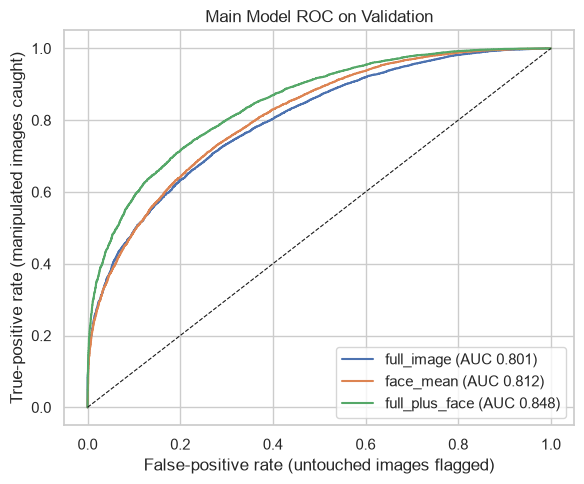

In [17]:
def select_on_validation(variants):
    # Compare the variants on validation, pick the best, and choose its two thresholds (validation only)
    val = data["validation"]
    val_images = val.drop_duplicates("image")
    cv_best = pd.DataFrame(cv_log).groupby("variant")["cv_auc_mean"].max()
    # Rows = image-caption pairs (how every model in the project is reported); distinct images = each photo once
    table = pd.DataFrame({
        v: {"val AUC (rows)": roc_auc_score(val["image_tampered"], val[f"p_{v}"]),
            "val AUC (distinct images)": roc_auc_score(val_images["image_tampered"], val_images[f"p_{v}"]),
            "val EER (rows)": binary_metrics(val["image_tampered"], val[f"p_{v}"])["EER"],
            "train grouped-CV AUC (images)": cv_best[v],
            "C": chosen_C[v]}
        for v in variants}).T
    selected = table["val AUC (rows)"].astype(float).idxmax()
    thr_f1 = best_f1_threshold(val["image_tampered"], val[f"p_{selected}"])
    # 99th percentile of untouched-image scores: only 1% of genuine validation images score above it
    thr_fpr1 = float(np.quantile(val.loc[val["image_tampered"] == 0, f"p_{selected}"], 1 - TARGET_FPR))
    return table, selected, thr_f1, thr_fpr1


def plot_roc(variants, labels, title):
    # ROC curve: for every possible threshold, the share of manipulated images caught (y) against the share of
    # untouched images wrongly flagged (x). Closer to the top-left corner is better; the diagonal is random guessing.
    val = data["validation"]
    fig, ax = plt.subplots(figsize=(6, 5))
    for v, label in zip(variants, labels):
        fpr, tpr, _ = roc_curve(val["image_tampered"], val[f"p_{v}"])
        ax.plot(fpr, tpr, label=f"{label} (AUC {roc_auc_score(val['image_tampered'], val[f'p_{v}']):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlabel("False-positive rate (untouched images flagged)")
    ax.set_ylabel("True-positive rate (manipulated images caught)")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()


val = data["validation"]
selection, SELECTED, threshold_f1, threshold_fpr1 = select_on_validation(VARIANTS)
display(selection.round(4))
# Freeze the configuration: best variant, its C, and both thresholds, all from validation only
CONFIG = {"variant": SELECTED, "C": chosen_C[SELECTED], "threshold_f1": threshold_f1, "threshold_fpr1": threshold_fpr1}
display(CONFIG)
plot_roc(VARIANTS, VARIANTS, "Main Model ROC on Validation")

**Reading the output.** `full_plus_face` has the highest validation AUC (0.848), ahead of `face_mean` (0.812) and `full_image` (0.801), so it is selected. Its validation AUC matches cross-validation on train (0.848), so the model is not overfitting. The frozen thresholds are **0.411** (best F1) and **0.936** (1% of untouched validation images flagged). From here on, only `full_plus_face` is used for the main model.

## 7. Error Analysis on Validation

Where does the selected model succeed and fail? Four breakdowns, all at the F1 threshold:
- **by `fake_cls`:** the share of rows flagged as tampered. For the six image manipulations this is the recall (higher is better). For `orig`, `text_swap` and `text_attribute` it is the false-positive rate (lower is better). A pixel-only model should flag text-only edits no more often than untouched originals.
- **by generator:** recall for each tool that made the manipulated images. InfoSwap and SimSwap are face-swap tools; HFGI and StyleCLIP are attribute editors.
- **AUC by publisher:** whether the model works equally well for photos from each news outlet. A big gap can point to a dataset shortcut rather than real detection (`03`, section 2.5).
- **AUC by number of valid face crops:** whether averaging over more faces weakens the face signal (section 4).

In [18]:
def publisher_of(df):
    # Manipulated files carry no publisher in their path, so each row takes the publisher of its article's original
    originals = pd.concat([d[d["fake_cls"] == "orig"] for d in raw.values()]).drop_duplicates("id")
    originals["image_source"] = originals["image"].str.split("/").str[1:3].str.join("/")
    return df["id"].map(originals.set_index("id")["image_source"].str.removeprefix("origin/"))


def breakdowns(df, score, threshold, variants):
    # The four breakdown tables described above, for one split, score column, threshold and set of variants
    out = {}
    # Share flagged per fake_cls: recall for the image manipulations, false-positive rate for orig and text-only edits
    out["by fake_cls"] = detection_rate_by_type(df, df[score], threshold)
    out["by fake_cls"]["image_tampered"] = out["by fake_cls"].index.map(image_tampered_from_fake_cls)
    # Recall per generator (manipulated images only)
    out["by generator"] = detection_rate_by_type(df[df["image_tampered"] == 1], df.loc[df["image_tampered"] == 1, score],
                                                 threshold, group_col="image_source")
    # AUC within each publisher (NaN if a group has only one class, as can happen in the smoke test)
    pub = publisher_of(df)
    out["AUC by publisher"] = pd.DataFrame({
        p: {"AUC": roc_auc_score(g["image_tampered"], g[score]) if g["image_tampered"].nunique() == 2 else np.nan,
            "rows": len(g), "% manipulated": 100 * g["image_tampered"].mean()}
        for p, g in df.assign(publisher=pub).dropna(subset=["publisher"]).groupby("publisher")}).T
    # AUC of each variant, grouped by the number of valid face crops (4 or more grouped together)
    faces_bucket = df["image"].map(images.set_index("image")["n_valid_faces"]).clip(upper=4).map({0: "0", 1: "1", 2: "2", 3: "3", 4: "4+"})
    out["AUC by valid face crops"] = pd.DataFrame({
        b: {**{v: roc_auc_score(g["image_tampered"], g[f"p_{v}"]) if g["image_tampered"].nunique() == 2 else np.nan
               for v in variants}, "rows": len(g)}
        for b, g in df.assign(bucket=faces_bucket).groupby("bucket")}).T
    return out


def show(tables):
    for name, table in tables.items():
        print(name)
        display(table.round(3))


val_breakdowns = breakdowns(val, f"p_{SELECTED}", threshold_f1, VARIANTS)
show(val_breakdowns)

by fake_cls


,flagged_rate,n,image_tampered
fake_cls,,,
text_attribute,0.393,825,0
orig,0.427,7473,0
text_swap,0.441,1894,0
face_swap&text_attribute,0.846,533,1
face_swap,0.869,4788,1
face_swap&text_swap,0.888,1163,1
face_attribute,0.903,3999,1
face_attribute&text_swap,0.913,964,1
face_attribute&text_attribute,0.918,487,1


by generator


,flagged_rate,n
image_source,,
manipulation/simswap,0.783,2216
manipulation/HFGI,0.886,2737
manipulation/infoswap,0.916,4268
manipulation/StyleCLIP,0.926,2713


AUC by publisher


,AUC,rows,% manipulated
bbc,0.861,4412.0,57.162
guardian,0.892,11504.0,54.442
usa_today,0.728,2730.0,54.505
washington_post,0.737,2970.0,55.926


AUC by valid face crops


,full_image,face_mean,full_plus_face,rows
1,0.769,0.814,0.837,499.0
2,0.811,0.818,0.857,12962.0
3,0.797,0.808,0.843,4871.0
4+,0.774,0.796,0.820,3794.0


**Reading the output** (validation):

- **Text-only edits:** flagged about as often as untouched originals (0.39 `text_attribute`, 0.44 `text_swap`, 0.43 `orig`). The model reacts to pixels, not captions. All three rates are high because the F1 threshold is lenient; section 8 shows the strict threshold.
- **Misses:** face swaps are missed slightly more often than attribute edits (recall 0.87 vs 0.90). SimSwap is the hardest generator (0.78 caught); StyleCLIP and InfoSwap are the easiest (0.93 and 0.92).
- **Publishers:** AUC is higher for the Guardian (0.89) and BBC (0.86) than for USA Today (0.73) and Washington Post (0.74). `03` found that Guardian fakes were re-compressed when DGM4 was built, so part of the Guardian signal may be that artefact rather than the edit. This is a limitation to report.
- **Face count:** `full_plus_face` AUC falls from 0.86 with two faces to 0.82 with four or more, the dilution expected from averaging. Images with a single face are few (499) and score slightly lower (0.84).

## 8. Test Evaluation

This is the only place the test labels are used for the main model. The configuration in `CONFIG` (variant, `C`, both thresholds) was fixed on validation and is applied unchanged.

The results table has four rows:
1. **majority class:** always predicts the most common `train_sample` label ("manipulated"), with no model at all. It is the floor a useful model must beat. Its AUC is 0.5 because it gives every image the same score.
2. **the model at the F1 threshold:** the main result.
3. **the same model at the 1% false-positive threshold.** AUC and EER are identical to row 2 because they do not depend on the threshold; only accuracy, precision, recall and F1 change.
4. **the main result again, without** the test rows that share an article or an exact image with `train_sample` (section 3).

`evaluate_on_test` is reused for the lightweight model in section 10.

,AUC,PR-AUC,EER,ACC,Precision,Recall,F1,threshold
majority class (always 1),0.5000,0.5306,0.5000,0.5306,0.5306,1.0000,0.6933,0.5000
"main model, F1 threshold",0.8536,0.8746,0.2385,0.7490,0.7123,0.8840,0.7889,0.4111
"main model, 1% FPR threshold",0.8536,0.8746,0.2385,0.6140,0.9762,0.2793,0.4343,0.9363
"main model, F1 threshold, excl. 18 rows seen in train_sample",0.8536,0.8746,0.2386,0.7490,0.7124,0.8839,0.7890,0.4111


,threshold,untouched called tampered (false alarms),untouched total,manipulated called tampered (caught),manipulated total
F1 threshold,0.411106,9605.0,23801.0,23782.0,26904.0
1% FPR threshold,0.936289,183.0,23801.0,7514.0,26904.0


,pred: untouched,pred: manipulated
true: untouched,14196,9605
true: manipulated,3122,23782


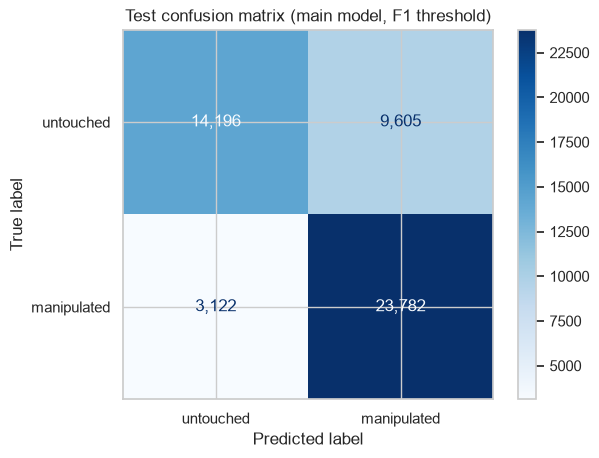

by fake_cls


,flagged_rate,n,image_tampered
fake_cls,,,
text_attribute,0.369,1973,0
orig,0.406,16876,0
text_swap,0.408,4952,0
face_swap&text_attribute,0.867,1118,1
face_swap,0.867,10515,1
face_swap&text_swap,0.874,2935,1
face_attribute&text_swap,0.899,2529,1
face_attribute,0.902,8921,1
face_attribute&text_attribute,0.915,886,1


by generator


,flagged_rate,n
image_source,,
manipulation/simswap,0.777,4868
manipulation/HFGI,0.877,6286
manipulation/infoswap,0.914,9700
manipulation/StyleCLIP,0.929,6050


AUC by publisher


,AUC,rows,% manipulated
bbc,0.866,9351.0,56.507
guardian,0.899,26577.0,53.806
usa_today,0.743,7291.0,54.670
washington_post,0.725,5994.0,55.622


AUC by valid face crops


,full_image,face_mean,full_plus_face,rows
0,NaN,NaN,NaN,1.0
1,0.774,0.835,0.851,1010.0
2,0.819,0.825,0.865,30304.0
3,0.799,0.811,0.844,11113.0
4+,0.783,0.791,0.824,8277.0


At the 1% false-positive threshold:


,flagged_rate,n
fake_cls,,
text_swap,0.005,4952
text_attribute,0.006,1973
orig,0.009,16876
face_attribute&text_swap,0.260,2529
face_swap,0.276,10515
face_swap&text_attribute,0.276,1118
face_attribute,0.282,8921
face_swap&text_swap,0.290,2935
face_attribute&text_attribute,0.314,886


In [19]:
def evaluate_on_test(selected, thr_f1, thr_fpr1, variants, name):
    # One test evaluation of a frozen configuration; displays every table and returns the results and breakdowns
    test = data["test"]
    score = test[f"p_{selected}"].to_numpy()
    y_test = test["image_tampered"].to_numpy()
    majority = int(data["train_sample"]["image_tampered"].mean() >= 0.5)  # most common training label
    seen = seen_in_train(test)
    results = pd.DataFrame({
        "majority class (always %d)" % majority: binary_metrics(y_test, np.full(len(y_test), float(majority))),
        f"{name}, F1 threshold": binary_metrics(y_test, score, thr_f1),
        f"{name}, 1% FPR threshold": binary_metrics(y_test, score, thr_fpr1),
        f"{name}, F1 threshold, excl. {seen.sum()} rows seen in train_sample": binary_metrics(y_test[~seen], score[~seen], thr_f1),
    }).T
    display(results.round(4))

    # What each threshold means in counts: how many test images of each kind are called tampered
    is_manip = y_test == 1
    display(pd.DataFrame({
        label: {"threshold": t,
                "untouched called tampered (false alarms)": int((score[~is_manip] >= t).sum()),
                "untouched total": int((~is_manip).sum()),
                "manipulated called tampered (caught)": int((score[is_manip] >= t).sum()),
                "manipulated total": int(is_manip.sum())}
        for label, t in [("F1 threshold", thr_f1), ("1% FPR threshold", thr_fpr1)]}).T)

    # Confusion matrix at the main threshold: rows = truth, columns = the model's decision
    cm = confusion_matrix(y_test, score >= thr_f1)
    display(pd.DataFrame(cm, index=["true: untouched", "true: manipulated"], columns=["pred: untouched", "pred: manipulated"]))
    ConfusionMatrixDisplay(cm, display_labels=["untouched", "manipulated"]).plot(cmap="Blues", values_format=",")
    plt.title(f"Test confusion matrix ({name}, F1 threshold)")
    plt.show()

    # Same four breakdowns as section 7, now on test, plus the flag rates at the strict threshold
    tables = breakdowns(test, f"p_{selected}", thr_f1, variants)
    show(tables)
    print("At the 1% false-positive threshold:")
    display(detection_rate_by_type(test, test[f"p_{selected}"], thr_fpr1).round(3))
    return results, tables


if RUN_TEST:
    results_test, test_breakdowns = evaluate_on_test(SELECTED, threshold_f1, threshold_fpr1, VARIANTS, "main model")
else:
    print("RUN_TEST is False: test set not evaluated.")

**Reading the output** (test, 50,705 rows):

- **Main result** (threshold 0.411): ROC-AUC 0.854, EER 0.239, accuracy 0.749, precision 0.712, recall 0.884, F1 0.789. The majority class gets accuracy 0.531 and F1 0.693, so the model clearly beats it. Test AUC matches validation (0.848), so tuning on validation did not overfit.
- **In counts:** 23,782 of 26,904 manipulated images are caught (88%), but 9,605 of 23,801 untouched images are also flagged (40%). That suits a test set where half the images are fake, not a real news feed.
- **Strict threshold** (0.936): 183 of 23,801 untouched images are flagged (0.8%), and 7,514 of 26,904 manipulated images are caught (28%). When it raises an alarm it is right 98% of the time (precision 0.976).
- **Overlap check:** removing the 18 rows seen in `train_sample` changes the metrics by at most 0.0001.
- **Breakdowns:** the same pattern as validation. Recall is 0.87 for `face_swap` and 0.90 for `face_attribute`, and SimSwap is the hardest generator (0.78). Text-only edits are flagged no more than originals at either threshold (about 0.5–0.9% at the strict one). Publisher AUC ranges from 0.73 (Washington Post) to 0.90 (Guardian).

## 9. Save Predictions

Row-level image scores of the **main model** for every row of `train_sample` (out-of-fold), `validation` and `test`, keyed by `row_id` from `02`:

| Column | Meaning |
|---|---|
| `row_id` | the team's stable row key from `02` |
| `split` | `train_sample`, `validation` or `test` |
| `id` | source article id |
| `image_tampered` | ground truth: 1 if the image was manipulated |
| `p_image_tampered` | the model's score; called tampered if ≥ the threshold in `image_model_thresholds.csv` |
| `p_image_fake` | identical copy under the name `05` and `src/evaluation.evaluate` use, so the fusion notebook can join it directly |

These are **image-level** predictions repeated on each row that shows the image. They say nothing about the caption, so they are not pair-level fake-news predictions.

Also saved:
- `image_model_thresholds.csv`: `image_fake` = F1 threshold, `image_fake_fpr1` = 1% false-positive threshold
- `image_model_metrics.csv`: the validation selection table and the test results
- `image_model_config.json`: variant, `C`, thresholds, cross-validation log, dataset and checkpoint revisions, library versions

The lightweight model's predictions are saved separately in section 10, as `image_model_light_*`.

In [20]:
def save_predictions(selected, thr_f1, thr_fpr1, prefix):
    # Write one prediction file per split plus the thresholds, with checks that nothing was lost or mangled
    outputs = {"train_sample_oof": "train_sample", "validation": "validation", "test": "test"}
    for name, split in outputs.items():
        df = data[split]
        p = df[f"p_{selected}"].to_numpy()
        frame = pd.DataFrame({"row_id": df["row_id"].to_numpy(), "split": split, "id": df["id"].to_numpy(),
                              "image_tampered": df["image_tampered"].to_numpy(), "p_image_tampered": p, "p_image_fake": p})
        # Guard against silent errors: one row per input row, unique keys, valid probabilities
        assert len(frame) == len(df) and frame["row_id"].is_unique
        assert frame["p_image_tampered"].between(0, 1).all() and frame["p_image_tampered"].notna().all()
        path = PREDICTIONS_DIR / f"{prefix}_{name}.parquet"
        frame.to_parquet(path, index=False)
        # Reload check: the saved file covers exactly 02's rows, in order
        assert pd.read_parquet(path)["row_id"].tolist() == df["row_id"].tolist()
        print(f"{path.relative_to(PROJECT_ROOT)}  {frame.shape}")
    pd.Series({"image_fake": thr_f1, "image_fake_fpr1": thr_fpr1}, name="threshold").to_frame().to_csv(
        PREDICTIONS_DIR / f"{prefix}_thresholds.csv")


save_predictions(SELECTED, threshold_f1, threshold_fpr1, "image_model")
metrics = selection.copy()
if RUN_TEST:
    metrics = pd.concat([metrics.assign(split="validation"), results_test.assign(split="test")])
metrics.to_csv(PREDICTIONS_DIR / "image_model_metrics.csv")
with open(PREDICTIONS_DIR / "image_model_config.json", "w") as f:
    json.dump({**run_info, **CONFIG, "embeddings_from_04": USE_04_EMBEDDINGS, "C_grid": C_GRID, "n_folds": N_FOLDS,
               "min_face_side": MIN_FACE_SIDE, "face_margin": FACE_MARGIN,
               "cv": [r for r in cv_log if r["variant"] in VARIANTS]}, f, indent=2, default=float)
print("saved thresholds, metrics and config to", PREDICTIONS_DIR.relative_to(PROJECT_ROOT))

results/predictions/image_model_train_sample_oof.parquet  (49943, 6)
results/predictions/image_model_validation.parquet  (22126, 6)
results/predictions/image_model_test.parquet  (50705, 6)
saved thresholds, metrics and config to results/predictions


## 10. Lightweight Model: ViT-B/32 for When Speed Matters

The main model uses two fairly heavy encoders. When **time matters**, a smaller encoder can be the better choice:
- **Volume.** A platform may receive many news photos a minute, and each must be scored before it is shown or shared. A slower model means a growing backlog or more GPUs.
- **Speed of spread.** A manipulated photo does most harm in its first hours, when it is shared fastest. A fast first screen can flag it early; a slower, stronger model can then re-check only the flagged ones.
- **Cheaper hardware.** A small encoder runs at a useful speed on a laptop CPU or a modest GPU.

The lightweight model uses **ViT-B/32** (`openai/clip-vit-base-patch32`) for both whole images and face crops: a base network of 12 layers that cuts the 224×224 input into only 7×7 = 49 squares of 32 px, giving 512 numbers per picture. Everything else is identical to the main model: the same face crops, the same three variants, the same `fit_variant`, its own validation selection and thresholds, and one test evaluation. Section 11 compares the two on accuracy and measured speed.

08 computes these embeddings itself (cached in `data/interim/image_model/`, about 70 minutes the first time on this Mac). Its predictions are saved separately as `image_model_light_*`.

In [21]:
# Embed every distinct whole image, then every valid face crop, with ViT-B/32. Cached chunks are reused on re-runs.
cached_index("full_vitb32", images[["image"]])
cached_index("faces_vitb32", faces[["image", "x1", "y1", "x2", "y2"]])
model, _, _ = load_clip(device, LIGHT_ENCODER)
print(f"{LIGHT_ENCODER} on {device}, {NUM_WORKERS} loader workers, {len(images):,} images + {len(faces):,} face crops")

start = time.time()
full_light = encode_images_chunked(model, ImageDataset(images["image"], model_name=LIGHT_ENCODER), device,
                                   cache_prefix=CACHE_DIR / "full_vitb32", num_workers=NUM_WORKERS)
print(f"whole images: {full_light.shape} in {(time.time() - start) / 60:.1f} min")
start = time.time()
face_light = encode_images_chunked(model, ImageDataset(faces["image"], face_boxes, model_name=LIGHT_ENCODER), device,
                                   cache_prefix=CACHE_DIR / "faces_vitb32", num_workers=NUM_WORKERS)
print(f"face crops: {face_light.shape} in {(time.time() - start) / 60:.1f} min")
del model

# One face embedding per image; the fallback is the image's own ViT-B/32 whole-image vector (same 512 numbers)
face_mean_light, n_used = mean_face_embedding(face_light, faces["image_idx"].to_numpy(), full_light)
assert (n_used == images["n_valid_faces"].to_numpy()).all()

FEATURES_LIGHT = {"light_full_image": full_light, "light_face_mean": face_mean_light,
                  "light_full_plus_face": np.hstack([full_light, face_mean_light])}
LIGHT_VARIANTS = list(FEATURES_LIGHT)
assert all(X.dtype == np.float32 and len(X) == len(images) and np.isfinite(X).all() for X in FEATURES_LIGHT.values())

# Same fitting as section 5
for variant, X in FEATURES_LIGHT.items():
    image_scores[variant], chosen_C[variant], log, final_models[variant] = fit_variant(variant, X)
    cv_log += log
    for s in SPLITS:
        data[s][f"p_{variant}"] = row_scores(data[s], variant)

openai/clip-vit-base-patch32 on mps, 8 loader workers, 110,030 images + 284,963 face crops


whole images: (110030, 512) in 0.0 min


face crops: (284963, 512) in 0.0 min


light_full_image: C=1.0, grouped CV AUC 0.742 (7s)


light_face_mean: C=1.0, grouped CV AUC 0.793 (13s)


light_full_plus_face: C=0.1, grouped CV AUC 0.811 (21s)


In [22]:
# Same validation selection as section 6, with the lightweight model's own thresholds
selection_light, SELECTED_LIGHT, threshold_f1_light, threshold_fpr1_light = select_on_validation(LIGHT_VARIANTS)
display(selection_light.round(4))
CONFIG_LIGHT = {"variant": SELECTED_LIGHT, "C": chosen_C[SELECTED_LIGHT],
                "threshold_f1": threshold_f1_light, "threshold_fpr1": threshold_fpr1_light}
display(CONFIG_LIGHT)

,val AUC (rows),val AUC (distinct images),val EER (rows),train grouped-CV AUC (images),C
light_full_image,0.7454,0.7400,0.3257,0.7421,1.0
light_face_mean,0.7950,0.7925,0.2919,0.7927,1.0
light_full_plus_face,0.8131,0.8099,0.2738,0.8115,0.1


{'variant': 'light_full_plus_face',
 'C': 0.1,
 'threshold_f1': 0.43468736484646797,
 'threshold_fpr1': 0.9242355823516846}

,AUC,PR-AUC,EER,ACC,Precision,Recall,F1,threshold
majority class (always 1),0.5000,0.5306,0.5000,0.5306,0.5306,1.0000,0.6933,0.5000
"lightweight model, F1 threshold",0.8195,0.8389,0.2685,0.7224,0.6876,0.8738,0.7696,0.4347
"lightweight model, 1% FPR threshold",0.8195,0.8389,0.2685,0.5738,0.9610,0.2052,0.3382,0.9242
"lightweight model, F1 threshold, excl. 18 rows seen in train_sample",0.8195,0.8389,0.2685,0.7224,0.6877,0.8738,0.7696,0.4347


,threshold,untouched called tampered (false alarms),untouched total,manipulated called tampered (caught),manipulated total
F1 threshold,0.434687,10681.0,23801.0,23509.0,26904.0
1% FPR threshold,0.924236,224.0,23801.0,5520.0,26904.0


,pred: untouched,pred: manipulated
true: untouched,13120,10681
true: manipulated,3395,23509


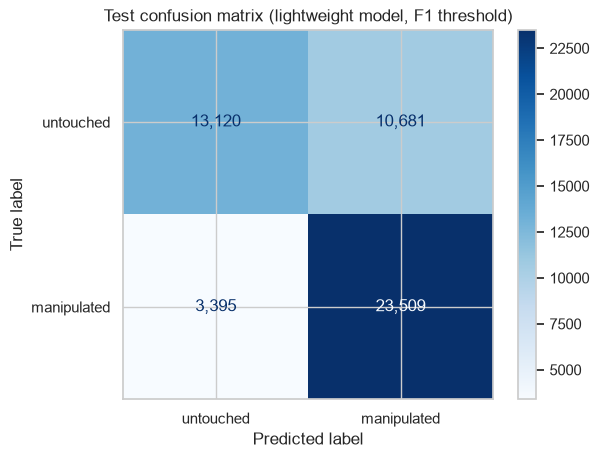

by fake_cls


,flagged_rate,n,image_tampered
fake_cls,,,
text_attribute,0.398,1973,0
orig,0.448,16876,0
text_swap,0.472,4952,0
face_swap&text_attribute,0.848,1118,1
face_swap,0.853,10515,1
face_swap&text_swap,0.856,2935,1
face_attribute&text_swap,0.889,2529,1
face_attribute&text_attribute,0.900,886,1
face_attribute,0.900,8921,1


by generator


,flagged_rate,n
image_source,,
manipulation/simswap,0.743,4868
manipulation/HFGI,0.873,6286
manipulation/infoswap,0.909,9700
manipulation/StyleCLIP,0.923,6050


AUC by publisher


,AUC,rows,% manipulated
bbc,0.819,9351.0,56.507
guardian,0.877,26577.0,53.806
usa_today,0.706,7291.0,54.670
washington_post,0.679,5994.0,55.622


AUC by valid face crops


,light_full_image,light_face_mean,light_full_plus_face,rows
0,NaN,NaN,NaN,1.0
1,0.752,0.814,0.831,1010.0
2,0.754,0.804,0.825,30304.0
3,0.747,0.791,0.815,11113.0
4+,0.743,0.779,0.806,8277.0


At the 1% false-positive threshold:


,flagged_rate,n
fake_cls,,
text_swap,0.008,4952
orig,0.010,16876
text_attribute,0.010,1973
face_attribute&text_swap,0.191,2529
face_swap&text_swap,0.195,2935
face_swap,0.197,10515
face_attribute,0.215,8921
face_swap&text_attribute,0.220,1118
face_attribute&text_attribute,0.257,886


results/predictions/image_model_light_train_sample_oof.parquet  (49943, 6)
results/predictions/image_model_light_validation.parquet  (22126, 6)
results/predictions/image_model_light_test.parquet  (50705, 6)


In [23]:
# Same single test evaluation as section 8
if RUN_TEST:
    results_test_light, test_breakdowns_light = evaluate_on_test(SELECTED_LIGHT, threshold_f1_light, threshold_fpr1_light,
                                                                 LIGHT_VARIANTS, "lightweight model")
save_predictions(SELECTED_LIGHT, threshold_f1_light, threshold_fpr1_light, "image_model_light")

**Reading the output.** The lightweight model follows the same pattern as the main one, a few points lower everywhere:
- **Variants on validation:** whole image 0.745, faces 0.795, both **0.813** (selected, C = 0.1). Its thresholds are 0.435 (best F1) and 0.924 (1% false-positive rate).
- **Test:** ROC-AUC 0.820, EER 0.269, accuracy 0.722, precision 0.688, recall 0.874, F1 0.770. At the strict threshold it catches 21% of manipulated images (5,520 of 26,904) with 224 false alarms.
- **Where it loses most:** the whole image. With 32 px squares, a 33 px face is a single square, so the whole-image vector carries little face detail (0.745 vs the main model's 0.801). The face crops recover most of it.

## 11. Main vs Lightweight

### 11.1 Accuracy

Each model is shown at its own validation-chosen threshold. Validation compares all six variants; test compares the two selected models once.

model,lightweight,main,gain
input,,,
full_image,0.745,0.801,0.056
face_mean,0.795,0.812,0.017
full_plus_face,0.813,0.848,0.035


,AUC,PR-AUC,EER,ACC,Precision,Recall,F1,threshold
"main (ViT-L/14 + ViT-B/16), F1 threshold",0.8536,0.8746,0.2385,0.7490,0.7123,0.8840,0.7889,0.4111
"main (ViT-L/14 + ViT-B/16), 1% FPR threshold",0.8536,0.8746,0.2385,0.6140,0.9762,0.2793,0.4343,0.9363
"lightweight (ViT-B/32), F1 threshold",0.8195,0.8389,0.2685,0.7224,0.6876,0.8738,0.7696,0.4347
"lightweight (ViT-B/32), 1% FPR threshold",0.8195,0.8389,0.2685,0.5738,0.9610,0.2052,0.3382,0.9242


,main,lightweight,rows,gain
bbc,0.866,0.819,9351.0,0.047
guardian,0.899,0.877,26577.0,0.022
usa_today,0.743,0.706,7291.0,0.037
washington_post,0.725,0.679,5994.0,0.046


,main,lightweight
fake_cls,,
face_attribute,0.902,0.900
face_attribute&text_attribute,0.915,0.900
face_attribute&text_swap,0.899,0.889
face_swap,0.867,0.853
face_swap&text_attribute,0.867,0.848
face_swap&text_swap,0.874,0.856
orig,0.406,0.448
text_attribute,0.369,0.398
text_swap,0.408,0.472


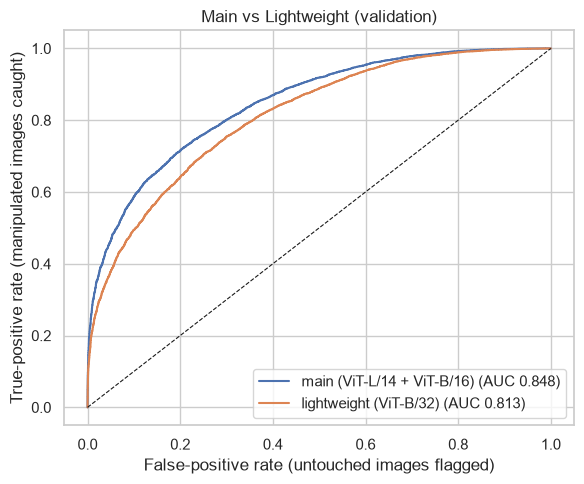

In [24]:
MODEL_OF = {**{v: "main" for v in VARIANTS}, **{v: "lightweight" for v in LIGHT_VARIANTS}}
ENCODER_OF = {"full_image": "ViT-L/14", "face_mean": "ViT-B/16", "full_plus_face": "ViT-L/14 + ViT-B/16",
              "light_full_image": "ViT-B/32", "light_face_mean": "ViT-B/32", "light_full_plus_face": "ViT-B/32"}
INPUT_OF = {v: v.removeprefix("light_") for v in [*VARIANTS, *LIGHT_VARIANTS]}

# Validation: every variant of both models, side by side by input
both_selection = pd.concat([selection, selection_light])
accuracy_val = pd.DataFrame({
    "input": [INPUT_OF[v] for v in both_selection.index], "model": [MODEL_OF[v] for v in both_selection.index],
    "encoder": [ENCODER_OF[v] for v in both_selection.index],
    "val AUC": both_selection["val AUC (rows)"].astype(float).to_numpy(),
    "val EER": both_selection["val EER (rows)"].astype(float).to_numpy(),
    "train grouped-CV AUC": both_selection["train grouped-CV AUC (images)"].astype(float).to_numpy()},
    index=both_selection.index)
display(accuracy_val.pivot(index="input", columns="model", values="val AUC").loc[["full_image", "face_mean", "full_plus_face"]]
        .assign(gain=lambda t: t["main"] - t["lightweight"]).round(3))

if RUN_TEST:
    test = data["test"]
    # Test: the two selected models, each at its own thresholds
    accuracy_test = pd.concat([
        results_test.iloc[1:3].rename(index=lambda r: r.replace("main model", f"main ({ENCODER_OF[SELECTED]})")),
        results_test_light.iloc[1:3].rename(index=lambda r: r.replace("lightweight model", f"lightweight ({ENCODER_OF[SELECTED_LIGHT]})")),
    ])
    display(accuracy_test.round(4))

    # Is the gain spread over all publishers, or concentrated on the Guardian (the re-compression shortcut in 03)?
    pub = publisher_of(test)
    by_pub = pd.DataFrame({
        p: {"main": roc_auc_score(g["image_tampered"], g[f"p_{SELECTED}"]),
            "lightweight": roc_auc_score(g["image_tampered"], g[f"p_{SELECTED_LIGHT}"]), "rows": len(g)}
        for p, g in test.assign(publisher=pub).dropna(subset=["publisher"]).groupby("publisher")
        if g["image_tampered"].nunique() == 2}).T
    by_pub["gain"] = by_pub["main"] - by_pub["lightweight"]
    display(by_pub.round(3))

    # Share flagged per fake_cls, each model at its own F1 threshold
    display(pd.DataFrame({
        "main": detection_rate_by_type(test, test[f"p_{SELECTED}"], threshold_f1)["flagged_rate"],
        "lightweight": detection_rate_by_type(test, test[f"p_{SELECTED_LIGHT}"], threshold_f1_light)["flagged_rate"],
    }).round(3))

plot_roc([SELECTED, SELECTED_LIGHT], [f"main ({ENCODER_OF[SELECTED]})", f"lightweight ({ENCODER_OF[SELECTED_LIGHT]})"],
         "Main vs Lightweight (validation)")

### 11.2 Speed

Speed is measured here, on this machine, for both models in the same way. The full embedding runs cannot be compared directly: `04`'s were run on Chloe's Mac, and 08's lightweight run used background data-loading processes. Instead, the same 500 random validation images are scored from scratch by each model's complete pipeline, in three parts:

| Part | What is timed |
|---|---|
| prepare | read the JPG from its zip, crop the faces, resize and normalise every picture to 224×224 (CPU) |
| encode | run the whole images and face crops through CLIP, 64 at a time (GPU) |
| score | average the face vectors and apply the fitted logistic regression |

Before timing, one batch is run through each encoder as a warm-up, so loading and compilation are not counted. **Latency** is also measured: 50 images scored one at a time, as a service answering one request would. As a check that the timed pipeline is the real one, the embeddings it produces must match the cached embeddings used for training (cosine > 0.99).

In [25]:
def sync():
    # GPU work is queued asynchronously; wait for it to finish before reading the clock
    if device == "mps":
        torch.mps.synchronize()
    elif device == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def embed(model, pixels, batch_size=64):
    out = []
    for i in range(0, len(pixels), batch_size):
        emb = model.get_image_features(pixel_values=pixels[i:i + batch_size].to(device)).pooler_output
        out.append(torch.nn.functional.normalize(emb, dim=-1).float().cpu())
    return torch.cat(out).numpy()


def vision_params(model):
    # Parameters of the image half of CLIP only (the text half is never used here)
    return sum(p.numel() for p in [*model.vision_model.parameters(), *model.visual_projection.parameters()])


bench = images[images["image"].isin(data["validation"]["image"])].sample(n=min(500, val["image"].nunique()),
                                                                          random_state=RANDOM_STATE)
bench_faces = faces[faces["image_idx"].isin(bench.index)]
owner = pd.Series(np.arange(len(bench)), index=bench.index).loc[bench_faces["image_idx"]].to_numpy()
bench_boxes = bench_faces[["x1", "y1", "x2", "y2"]].to_numpy().tolist()
print(f"benchmark: {len(bench)} validation images with {len(bench_faces)} face crops")


def benchmark(name, image_encoder, face_encoder, variant, cached_full, cached_faces):
    models = {enc: load_clip(device, enc)[0] for enc in {image_encoder, face_encoder}}
    for m in models.values():  # warm-up, not timed
        embed(m, torch.zeros(64, 3, 224, 224))
    sync()

    # Prepare: read, crop, resize and normalise (main process only, so both models are timed the same way)
    t0 = time.perf_counter()
    full_ds = ImageDataset(bench["image"], model_name=image_encoder)
    face_ds = ImageDataset(bench_faces["image"], bench_boxes, model_name=face_encoder)
    full_px = torch.stack([full_ds[i] for i in range(len(full_ds))])
    face_px = torch.stack([face_ds[i] for i in range(len(face_ds))])
    t1 = time.perf_counter()
    # Encode
    full_e = embed(models[image_encoder], full_px)
    face_e = embed(models[face_encoder], face_px)
    sync()
    t2 = time.perf_counter()
    # Score (the pooled-face fallback is never needed here: every benchmark image has a valid face)
    face_mean_e, n = mean_face_embedding(face_e, owner, np.zeros((len(bench), face_e.shape[1]), np.float32))
    X = {"full_image": full_e, "face_mean": face_mean_e, "full_plus_face": np.hstack([full_e, face_mean_e])}[INPUT_OF[variant]]
    final_models[variant].predict_proba(X)
    t3 = time.perf_counter()

    # The timed pipeline must reproduce the embeddings the model was trained on
    cos_full = np.einsum("ij,ij->i", full_e, cached_full[bench.index.to_numpy()])
    cos_face = np.einsum("ij,ij->i", face_e, cached_faces[bench_faces.index.to_numpy()])
    assert np.median(cos_full) > 0.99 and np.median(cos_face) > 0.99, f"{name}: benchmark embeddings differ from the cache"

    # Latency: 50 images one at a time, each with its own faces, from file to score
    latencies = []
    for i in range(min(50, len(bench))):
        s = time.perf_counter()
        own = np.flatnonzero(owner == i)
        px_full = full_ds[i][None]
        px_face = torch.stack([face_ds[j] for j in own])
        e_full = embed(models[image_encoder], px_full)
        e_face = embed(models[face_encoder], px_face)
        sync()
        pooled = e_face.mean(axis=0, keepdims=True)
        pooled /= np.linalg.norm(pooled, axis=1, keepdims=True)
        x = {"full_image": e_full, "face_mean": pooled, "full_plus_face": np.hstack([e_full, pooled])}[INPUT_OF[variant]]
        final_models[variant].predict_proba(x)
        latencies.append(time.perf_counter() - s)

    params = sum(vision_params(m) for m in models.values())
    del models
    total = t3 - t0
    return {"encoders": ENCODER_OF[variant], "image-encoder parameters (M)": params / 1e6,
            "numbers per image": X.shape[1],
            "prepare (ms/image)": 1000 * (t1 - t0) / len(bench), "encode (ms/image)": 1000 * (t2 - t1) / len(bench),
            "score (ms/image)": 1000 * (t3 - t2) / len(bench), "total (ms/image)": 1000 * total / len(bench),
            "images per second": len(bench) / total, "minutes per 100,000 images": 100_000 * total / len(bench) / 60,
            "latency, one image at a time (median ms)": 1000 * np.median(latencies),
            "embedding check (median cosine)": float(min(np.median(cos_full), np.median(cos_face)))}


speed = pd.DataFrame({
    "main": benchmark("main", MAIN_IMAGE_ENCODER, MAIN_FACE_ENCODER, SELECTED, full_main, face_main),
    "lightweight": benchmark("lightweight", LIGHT_ENCODER, LIGHT_ENCODER, SELECTED_LIGHT, full_light, face_light),
})
speed["lightweight is faster by"] = [np.nan] * len(speed)
for row, better_low in [("encode (ms/image)", True), ("total (ms/image)", True),
                        ("latency, one image at a time (median ms)", True)]:
    speed.loc[row, "lightweight is faster by"] = speed.loc[row, "main"] / speed.loc[row, "lightweight"]
speed

benchmark: 500 validation images with 1294 face crops


,main,lightweight,lightweight is faster by
encoders,ViT-L/14 + ViT-B/16,ViT-B/32,NaN
image-encoder parameters (M),390.158848,87.849216,NaN
numbers per image,1280,1024,NaN
prepare (ms/image),7.489979,6.917244,NaN
encode (ms/image),135.892037,22.979988,5.913495
score (ms/image),0.092883,0.063748,NaN
total (ms/image),143.474899,29.96098,4.788725
images per second,6.96986,33.376745,NaN
"minutes per 100,000 images",239.124832,49.934967,NaN
"latency, one image at a time (median ms)",189.300833,38.211208,4.954066


In [26]:
# Save the full comparison: validation by variant, test for both selected models, and the speed table
comparison_out = [accuracy_val.assign(section="validation")]
if RUN_TEST:
    comparison_out.append(accuracy_test.assign(section="test"))
comparison_out.append(speed.T.assign(section="speed"))
pd.concat(comparison_out).to_csv(PREDICTIONS_DIR / "image_model_comparison.csv")
with open(PREDICTIONS_DIR / "image_model_light_config.json", "w") as f:
    json.dump({**run_info, **CONFIG_LIGHT, "C_grid": C_GRID, "n_folds": N_FOLDS, "min_face_side": MIN_FACE_SIDE,
               "face_margin": FACE_MARGIN, "cv": [r for r in cv_log if r["variant"] in LIGHT_VARIANTS]},
              f, indent=2, default=float)
print("saved image_model_comparison.csv and image_model_light_config.json to", PREDICTIONS_DIR.relative_to(PROJECT_ROOT))

saved image_model_comparison.csv and image_model_light_config.json to results/predictions


**Reading the output.**

**Accuracy.** The main model is better on every measure:

| | Main | Lightweight | Difference |
|---|---|---|---|
| Validation AUC (both inputs) | 0.848 | 0.813 | +0.035 |
| Test AUC | **0.854** | 0.820 | +0.034 |
| Test EER | **0.239** | 0.269 | −0.030 |
| Test F1 (own F1 threshold) | **0.789** | 0.770 | +0.019 |
| Caught at 1% false alarms (test) | **28%** | 21% | +7 points |

- **By input:** the gain is largest for the whole image (+0.056) and smallest for face crops (+0.017). Face crops already give each face the full resolution, so a finer encoder adds less there.
- **By publisher:** the gain is smallest for the Guardian (+0.022) and largest for BBC (+0.047) and Washington Post (+0.046), so it does not come from the Guardian re-compression shortcut.
- **False alarms:** at the F1 threshold the main model flags fewer untouched originals (0.41 vs 0.45) and fewer `text_swap` rows (0.41 vs 0.47).

**Speed** (500 validation images, this Mac's GPU):

| | Main | Lightweight | |
|---|---|---|---|
| Image-encoder parameters | 390 M | 88 M | 4.4× smaller |
| Encoding time per image | about 215–240 ms | about 30 ms | about 7× faster |
| Total time per image | about 225–250 ms | about 38–40 ms | about 6× faster |
| Images per second | about 4–4.5 | about 25–27 | |
| Time for 100,000 images | about 6 hours | about 1 hour | |
| One image at a time (latency) | about 240–290 ms | about 45 ms | about 5–6× faster |

Exact times vary by a few percent between runs (the table above is this run's); the figures here are rounded over repeated runs. Almost all of the time is in CLIP itself. Reading and cropping take about 8 ms per image for both models, and the logistic regression takes under 0.1 ms. The timed pipeline reproduces the training embeddings exactly (cosine 1.0), so these are the speeds of the models evaluated above.

**Which to use.** The main model is more accurate. The lightweight model gives up about 0.034 AUC and 0.019 F1 for about 6× the speed. For a platform that must screen every photo as it arrives, or runs on modest hardware, the lightweight model is the practical first screen. A two-stage setup gets most of both: the lightweight model screens everything, and the main model re-checks only the photos it flags. Absolute times depend on the machine; the ratio between the two models is what carries over.

# Summary

**Task.** `p_image_tampered` is the probability that the image itself was manipulated (`face_swap` or `face_attribute`, with or without a caption edit). It is an image-level score, not a pair-level fake-news prediction, so untouched photos with swapped or flipped captions are negatives.

**Method.** Frozen CLIP embeddings feed a scaled logistic regression, fit on the 44,857 distinct images of `train_sample`. `C` is chosen by 5-fold CV grouped by article. The variant and thresholds are chosen on validation, and each chosen model is evaluated once on test. Face crops come from the provided `mtcnn_boxes`, with the same rule for both classes: clipped to the image, at least 16 px per side, 20% margin. They are averaged per image, with a whole-image fallback for the one image that has none. `fake_image_box`, captions, paths and ids are never inputs. Two models use the same method with different encoders:
- **Main:** ViT-L/14 for whole images and ViT-B/16 for faces. The embeddings were computed in notebook `04` and reused here after two alignment checks.
- **Lightweight:** ViT-B/32 for both, computed here.

**Validation AUC (variant selection)**

| Variant | Main | Lightweight |
|---|---|---|
| whole image | 0.801 | 0.745 |
| face crops | 0.812 | 0.795 |
| **both (selected)** | **0.848** | **0.813** |

**Test (50,705 rows, each model at its own validation-chosen F1 threshold)**

| Model | Threshold | ROC-AUC | EER | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|
| Majority class (always "manipulated") | – | 0.500 | 0.500 | 0.531 | 0.531 | 1.000 | 0.693 |
| **Main** (ViT-L/14 + ViT-B/16) | 0.411 | **0.854** | **0.239** | **0.749** | **0.712** | **0.884** | **0.789** |
| Lightweight (ViT-B/32) | 0.435 | 0.820 | 0.269 | 0.722 | 0.688 | 0.874 | 0.770 |

At the strict 1% false-positive threshold, the main model catches 28% of manipulated images and the lightweight model 21%.

**Speed** (this Mac, 500 validation images): main about 225–250 ms per image (about 4–4.5 images/s), lightweight about 40 ms (about 25–27 images/s), **about 6× faster**. Scoring 100,000 photos takes about 6.2 hours with the main model and about 1 hour with the lightweight one.

**Findings**
- **What the faces look like** (section 4.1, `train_sample`):
  - 2.59 valid faces per image on average, the same for both classes, so face count is not a shortcut.
  - A typical face is about 33 px wide after the 224 px resize.
  - The edited face is the largest one in only 66.5% of manipulated images, which is why faces are averaged.
- **Larger encoders help most on the whole image** (+0.056 AUC), where small squares keep face detail, and least on face crops (+0.017).
- **Averaging dilutes one edited face among several.** The main model's AUC falls from 0.865 with two faces to 0.824 with four or more (test).
- **Misses by type** (main, test): recall is 0.867 for `face_swap` and 0.902 for `face_attribute`. SimSwap is the hardest generator (0.777 caught) and StyleCLIP the easiest (0.929).
- **Text-only edits are not flagged more than originals:** 0.406 for `orig`, 0.408 for `text_swap`, 0.369 for `text_attribute` (main, F1 threshold). The model responds to pixels, not captions.

**Checks**
- **Labels:** rebuilt from `fake_cls` tags; they match `02`'s `image_fake` on every row.
- **Files:** all 206,362 distinct images of the official splits decode, and none are missing.
- **Overlap:** no article ids or image paths are shared across splits. Some byte-identical images are, for example 56 between train and test. Only 18 test rows share an exact image with `train_sample`, and excluding them changes the metrics by at most 0.0001.
- **Crop rule:** the share of boxes dropped is similar for both classes (3.7% untouched vs 2.8% manipulated).
- **`04`'s embeddings:** identical to its per-row copies, and re-embedded face crops match with cosine 1.0000.

**Limitations**
- **Possible publisher shortcut.** AUC is higher on the Guardian (0.899) and BBC (0.866) than on USA Today (0.743) and the Washington Post (0.725). `03` found that Guardian fakes were re-compressed during dataset construction, so part of the signal may be compression traces rather than the edit. The main model's gain over the lightweight one is smallest on the Guardian, so the gain itself is not the shortcut.
- **Test prevalence is unrealistic.** The test set is 53% manipulated, and the F1 threshold flags 40% of untouched images. At a realistic 1% false-positive rate, the main model catches 28% of manipulated images.
- **Scope of the setup.** The encoders are frozen, training uses a third of train, and generators outside DGM4 are untested.
- **Pooling choice.** Mean pooling over faces weakens the signal from one edited face. Max-pooling or multiple-instance learning would need face-level supervision or a different objective.
- **Speed figures are for one machine** (an Apple-silicon Mac with MPS). The ratio between the models is more reliable than the absolute times.

# Method Justification and Uncertainty

### Why logistic regression on frozen CLIP, and not a neural network

1. **The neural network is already there: it is CLIP.** CLIP is a large network pre-trained on hundreds of millions of image–caption pairs; its image half alone has about 300 million parameters for ViT-L/14. Using it frozen brings that learned visual knowledge without training it on our 45,000 photos, which would risk overfitting and need far more compute.
2. **A linear classifier on frozen CLIP features is an established detector.** Ojha et al. (2023, *Towards Universal Fake Image Detectors*) showed that a linear probe on frozen CLIP features detects generated images well. Our results agree: the main model reaches test AUC 0.854.
3. **A more flexible classifier on top is expected to add little.** CLIP's vectors are built so that simple, near-linear rules separate many kinds of image. In notebook `05`, a non-linear model (gradient boosting) beat logistic regression by only 0.015 AUC on similar CLIP-based features.
4. **It is simple to train and hard to overfit.** It has one hyperparameter (`C`), chosen by grouped cross-validation, and train-CV and validation AUC agree (0.848 and 0.848). It is fast enough that every choice in this notebook could be tested rather than assumed.
5. **It is transparent, though not fully interpretable.** The decision is a weighted sum of the embedding numbers, with no hidden layers. The individual CLIP numbers have no plain meaning, though, so the model's behaviour is explained through the breakdowns (by edit type, generator, publisher and face count) rather than through its weights.
6. **It is the baseline the project needs.** The project compares image-only, text-only and multimodal models. A simple, well-tested image model is a clear reference point for that comparison.

**Where a neural network would be the right next step.** The model's clearest weakness is averaging the faces: only one face is edited, and its signal is diluted as the number of faces grows (AUC 0.865 with two faces, 0.824 with four or more). A small network that scores each face separately and learns to focus on the most suspicious one could address this. It would learn from the image label alone ("something in this photo was edited"), without `fake_image_box`; this is called multiple-instance learning. That targets the known weakness directly, so it is a better next step than a larger classifier on the averaged vector. It is left as future work.

### How certain are the test results?

A single test score does not show how much it would change on a different sample of news photos. The cell below estimates this by **bootstrapping**:
1. Draw a new test set of the same size by sampling articles with replacement.
2. Re-score both models on it, with their thresholds still fixed from validation.
3. Repeat 1,000 times.

The middle 95% of the resulting scores is the 95% confidence interval. Whole articles are resampled rather than single rows, because rows of the same article share a photo or a story and are not independent.

In [27]:
if RUN_TEST:
    test = data["test"]
    y = test["image_tampered"].to_numpy()
    models_ci = {"main": (test[f"p_{SELECTED}"].to_numpy(), threshold_f1),
                 "lightweight": (test[f"p_{SELECTED_LIGHT}"].to_numpy(), threshold_f1_light)}

    # Each row's article, as an index; one bootstrap sample = a count of how often each article was drawn,
    # used as a weight on all of that article's rows (equivalent to copying the article that many times)
    article_of_row = pd.factorize(test["id"])[0]
    n_articles = article_of_row.max() + 1
    rng = np.random.default_rng(RANDOM_STATE)
    N_BOOT = 1000

    draws = {"main AUC": [], "lightweight AUC": [], "main F1": [], "lightweight F1": [], "AUC gain (main - lightweight)": []}
    start = time.time()
    for _ in range(N_BOOT):
        w = np.bincount(rng.integers(0, n_articles, n_articles), minlength=n_articles)[article_of_row]
        auc = {}
        for name, (score, thr) in models_ci.items():
            auc[name] = roc_auc_score(y, score, sample_weight=w)
            draws[f"{name} AUC"].append(auc[name])
            draws[f"{name} F1"].append(f1_score(y, score >= thr, sample_weight=w))
        draws["AUC gain (main - lightweight)"].append(auc["main"] - auc["lightweight"])

    # Point estimate on the real test set, and the middle 95% of the bootstrap draws
    point = {"main AUC": roc_auc_score(y, models_ci["main"][0]), "lightweight AUC": roc_auc_score(y, models_ci["lightweight"][0]),
             "main F1": f1_score(y, models_ci["main"][0] >= threshold_f1),
             "lightweight F1": f1_score(y, models_ci["lightweight"][0] >= threshold_f1_light)}
    point["AUC gain (main - lightweight)"] = point["main AUC"] - point["lightweight AUC"]
    ci = pd.DataFrame({k: {"test value": point[k], "95% CI low": np.percentile(v, 2.5), "95% CI high": np.percentile(v, 97.5)}
                       for k, v in draws.items()}).T
    ci["share of draws where main is better"] = np.nan
    ci.loc["AUC gain (main - lightweight)", "share of draws where main is better"] = np.mean(np.array(draws["AUC gain (main - lightweight)"]) > 0)
    print(f"{N_BOOT} bootstrap samples of {n_articles:,} test articles in {time.time() - start:.0f}s")
    ci.to_csv(PREDICTIONS_DIR / "image_model_confidence_intervals.csv")
    display(ci.round(4))
else:
    print("RUN_TEST is False: no confidence intervals.")

1000 bootstrap samples of 18,360 test articles in 17s


,test value,95% CI low,95% CI high,share of draws where main is better
main AUC,0.8536,0.8504,0.8567,NaN
lightweight AUC,0.8195,0.8161,0.8231,NaN
main F1,0.7889,0.7856,0.7922,NaN
lightweight F1,0.7696,0.7664,0.7726,NaN
AUC gain (main - lightweight),0.0341,0.0309,0.0370,1.0


**Reading the output.** The test results are precise: every 95% confidence interval is narrow, about ±0.003.
- **Main model:** AUC 0.854 (95% CI 0.850–0.857), F1 0.789 (0.786–0.792).
- **Lightweight model:** AUC 0.820 (0.816–0.823), F1 0.770 (0.766–0.773).
- **The gain is real:** the main model beats the lightweight one by 0.034 AUC (0.031–0.037), and it was better in all 1,000 bootstrap samples.

With 50,705 test rows from 18,360 articles, sampling noise is small. Systematic issues, such as the Guardian shortcut or generators outside DGM4, matter more than chance for how far these numbers carry over.